# slide_ja.pptx のプロット(8 図)

`docs/slide/slide_ja.pptx` に貼っている 8 枚のプロットを、このフォルダの `csv/` だけから作り直す。

1. **作図用 CSV を作る**:元データ(`csv/` 内の解析結果のコピー)を集計し、図に描く値そのものを `csv/slideNN_*.csv` に書き出す。
2. **作図する**:`csv/slideNN_*.csv` だけを読んで `png/`・`pdf/` に図を出力する。

| スライド | 作図用 CSV | 図 | 元データ |
|---|---|---|---|
| 16 | `slide16_sweetspot.csv` | `slide_sweetspot` | `solver_summary.csv` |
| 17 | `slide17_depth.csv` | `slide_depth` | `solver_summary.csv` |
| 18 | `slide18_loop_alpha.csv` | `slide_loop_alpha` | `loop_alpha_sweep.csv` |
| 19 | `slide19_confirm2.csv` | `slide_confirm2` | `confirm2_curves.csv` |
| 21 | `slide21_energy_hist.csv` | `slide_energy_hist` | `energy_hist.csv` |
| 22 | `slide22_retune_fixedfm.csv`、`slide22_retune_loop.csv` | `slide_retune_robustness` | `fixedfm_schedules.csv`、`loop_alpha_sweep.csv` |
| 23 | `slide23_paired_ranks.csv` | `slide_paired_ranks` | `confirm_final_ranks.csv` |
| 24 | `slide24_explore.csv` | `slide_explore_L678` | `explore_curves.csv` |

8 図とも日本語・スライド実寸(7.4 × 5.0 インチ)で、手法の色を全図で揃えて描く(2026-11-12 統一)。
使い方:`python plot.py`(全部)、またはこの Notebook を先頭から実行。

In [1]:
from pathlib import Path
import csv
import sys

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image

try:
    HERE = Path(__file__).resolve().parent
except NameError:                      # Notebook: run from this folder
    HERE = Path.cwd()
CSV = HERE / "csv"
PROJECT = HERE.parents[2]
sys.path.insert(0, str(PROJECT / "src"))
BASE_RC = {k: v for k, v in matplotlib.rcParams.items() if k != "backend"}   # defaults before aps_style changes them
import aps_style as S                  # paper style (slides 21-24); importing it changes rcParams, so each figure uses rc_context

IN_NOTEBOOK = "ipykernel" in sys.modules

# slide style (slides 16-19): Japanese gothic, >= 13 pt, drawn at the size placed on the slide
FAMILY = "Hiragino Sans" if any(f.name == "Hiragino Sans" for f in font_manager.fontManager.ttflist) else "YuGothic"
JA_RC = {
    **BASE_RC,
    "font.family": FAMILY, "font.size": 14, "axes.labelsize": 14, "xtick.labelsize": 13, "ytick.labelsize": 13,
    "legend.fontsize": 13, "mathtext.fontset": "stix", "axes.linewidth": 1.0, "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True, "axes.unicode_minus": False, "legend.frameon": False, "savefig.dpi": 300, "pdf.fonttype": 42,
}
BLUE, ORANGE, GREEN, PURPLE, GRAY = "#2a78d6", "#e8682f", "#1a9e6e", "#7b4fb3", "#8c8c8c"
M = {   # one style per method, same on every slide
    "XY-FMQAOA": dict(color=BLUE, ls="-", lw=3.0, label="XY-FMQAOA（$\\lambda=0$）"),
    "alpha1": dict(color="black", ls="--", lw=2.0, label="SA，$\\alpha=1$（調整済み）"),
    "alpha100": dict(color=ORANGE, ls="-", lw=2.0, label="SA，$\\alpha=100$（大きすぎ）"),
    "alpha0.3": dict(color=GREEN, ls="-.", lw=2.0, label="SA，$\\alpha=0.3$（小さすぎ）"),
    "CatSA": dict(color=PURPLE, ls=":", lw=2.4, label="カテゴリ型 SA"),
    "RandomFM": dict(color=GRAY, ls="--", lw=1.6, label="ランダム提案 + FM 選択"),
}
ALPHAS = [0.3, 1, 3, 10, 30, 100, 1000]
ATICK = ["0.3", "1", "3", "10", "30", "100", "1000"]


def read(name):
    """CSV -> list of dicts; numbers become float, empty cells None."""
    def conv(v):
        if v == "":
            return None
        try:
            return float(v)
        except ValueError:
            return v
    with open(CSV / name, encoding="utf-8") as f:
        return [{k: conv(v) for k, v in r.items()} for r in csv.DictReader(f)]


def write(name, rows):
    keys = list(dict.fromkeys(k for r in rows for k in r))
    with open(CSV / name, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, keys)
        w.writeheader()
        w.writerows(rows)
    print(f"csv/{name}: {len(rows)} rows")


def save(fig, stem, dpi=None, tight=False):
    """png/<stem>.png (opaque RGB: PowerPoint's PDF export greys out RGBA images) and pdf/<stem>.pdf."""
    kw = dict(facecolor="white", bbox_inches="tight" if tight else None)
    if tight:
        kw["pad_inches"] = 0.02
    for ext in ("png", "pdf"):
        (HERE / ext).mkdir(exist_ok=True)
        fig.savefig(HERE / ext / f"{stem}.{ext}", dpi=dpi, **kw)
    plt.close(fig)
    png = HERE / "png" / f"{stem}.png"
    Image.open(png).convert("RGB").save(png)
    print(f"png/{stem}.png, pdf/{stem}.pdf")
    if IN_NOTEBOOK:
        from IPython.display import Image as IPImage, display
        display(IPImage(filename=str(png), width=900))


def alpha_axis(ax):
    ax.set_xscale("log"); ax.set_xticks(ALPHAS); ax.set_xticklabels(ATICK); ax.minorticks_off(); ax.set_xlim(0.22, 1400)


def num(x):
    """'1' for 1.0, '0.3' for 0.3 (condition names use %g)."""
    return f"{x:g}"

## 1. 作図用 CSV を作る

元データ(`csv/` の解析結果コピー、SHA-256 は `SHA256SUMS.txt`)から、各図に描く点・線の値を計算して書き出す。
集計の決まり:固定 FM の値は 5 個の FM(Seed)の中央値と四分位(`solver_summary.csv` で集計済み)、閉ループの値は Seed ごとの最良順位を Seed 間で集計。
四分位は `numpy.percentile` の線形補間。

In [2]:
def build_slide16():
    """Fixed FM, L = 6-8: capture rate of the FM minimum, sample FM percentile, feasible fraction vs alpha (median of 5 FMs)."""
    d = {(int(r["layers"]), r["sampler"], r["metric"]): r for r in read("solver_summary.csv")}
    rows = []
    for L in (6, 7, 8):
        for a in ALPHAS:
            g = lambda m: d[(L, f"SA-a{num(a)}", m)]["median"] if (L, f"SA-a{num(a)}", m) in d else None
            rows.append({"layers": L, "alpha": a, "capture_median": g("capture"), "sample_fm_pct_median": g("sample_fm_pct"),
                         "feasible_median": g("feasible"), "n_fm": 5})
    write("slide16_sweetspot.csv", rows)


def build_slide17():
    """Fixed FM: normalized FM gap of the selected candidate. XY-QAOA (CVaR10) over depth p, SA alpha and random as references."""
    d = {(int(r["layers"]), r["sampler"], r["metric"]): r for r in read("solver_summary.csv")}
    rows = []
    for L in (6, 7, 8):
        for p in range(1, 7):
            r = d[(L, f"XY-p{p}-cvar10", "norm_gap")]
            rows.append({"layers": L, "method": "XY-FMQAOA", "p": p, "norm_gap_median": r["median"], "norm_gap_q25": r["q25"], "norm_gap_q75": r["q75"]})
        for a in (1, 3, 10, 100):
            r = d[(L, f"SA-a{a}", "norm_gap")]
            rows.append({"layers": L, "method": f"SA-a{a}", "p": None, "norm_gap_median": r["median"], "norm_gap_q25": r["q25"], "norm_gap_q75": r["q75"]})
        r = d[(L, "RandomFM", "norm_gap")]
        rows.append({"layers": L, "method": "RandomFM", "p": None, "norm_gap_median": r["median"], "norm_gap_q25": r["q25"], "norm_gap_q75": r["q75"]})
    write("slide17_depth.csv", rows)


def _rank_stats(v):
    v = np.asarray(v, float)
    return {"n_seeds": len(v), "best_rank_median": float(np.median(v)), "best_rank_q25": float(np.percentile(v, 25)),
            "best_rank_q75": float(np.percentile(v, 75)), "n_optimum": int((v == 1).sum())}


def build_slide18():
    """Closed loop, L = 7, 15 seeds: best rank after 100 evaluations (median, IQR, seeds at the optimum) per alpha, XY and random."""
    by = {}
    for r in read("loop_alpha_sweep.csv"):
        by.setdefault(r["condition"], []).append(r["best_rank"])
    rows = [{"condition": f"alpha{num(a)}", "alpha": a, **_rank_stats(by[f"alpha{num(a)}"])} for a in ALPHAS]
    rows += [{"condition": c, "alpha": None, **_rank_stats(by[c])} for c in ("XY-FMQAOA", "RandomFM", "Adaptive")]
    write("slide18_loop_alpha.csv", rows)


def _curve_rows(rows, conds, key=()):
    """Median best rank and fraction at the optimum vs evaluations (40-100), over seeds. key = extra grouping columns."""
    out = []
    groups = {}
    for r in rows:
        if r["condition"] in conds:
            groups.setdefault(tuple(r[k] for k in key) + (r["condition"],), {}).setdefault(r["seed"], {})[int(r["evaluations"])] = r["best_rank"]
    for g, seeds in groups.items():
        E = np.arange(40, 101)
        A = []
        for t in seeds.values():
            v, last = [], None
            for e in E:            # carry the last value forward if an evaluation count is missing
                last = t.get(e, last)
                v.append(last)
            A.append(v)
        A = np.array(A, float)
        for i, e in enumerate(E):
            out.append({**dict(zip(key, g[:-1])), "condition": g[-1], "evaluations": int(e), "n_seeds": len(A),
                        "best_rank_median": float(np.median(A[:, i])), "frac_optimum": float((A[:, i] == 1).mean())})
    return out


def build_slide19():
    """Second confirmation, L = 7, 30 seeds: median best rank and fraction of seeds at the optimum vs evaluations."""
    write("slide19_confirm2.csv", _curve_rows(read("confirm2_curves.csv"), ["XY-FMQAOA", "alpha1", "CatSA", "alpha100", "alpha0.3"]))


def build_slide21():
    """Fixed FM, L = 7: histogram of the FM percentile of feasible samples, pooled over 5 FMs, as a density."""
    rows = [r for r in read("energy_hist.csv") if r["layers"] == 7]
    out = []
    for smp in ("SA-auto-a1", "SA-auto-a10", "SA-auto-a100", "XY-p4-cvar10", "RandomFM"):
        r = [x for x in rows if x["sampler"] == smp]
        lo = sorted({x["bin_lo"] for x in r})
        cnt = np.array([sum(x["count"] for x in r if x["bin_lo"] == b) for b in lo], float)
        dens = cnt / cnt.sum() / (lo[1] - lo[0])
        for b, c, dd in zip(lo, cnt, dens):
            out.append({"layers": 7, "sampler": smp, "bin_lo": b, "bin_hi": round(b + (lo[1] - lo[0]), 10), "count_pooled": int(c), "density": float(dd)})
    write("slide21_energy_hist.csv", out)


SCHEDULES = ("auto", "fmscale", "wide10x", "fmscale10x")


def build_slide22():
    """(a)-(c) fixed FM: median sample FM percentile per SA temperature schedule and alpha (5 FMs), with random and XY p=4;
    (d) closed loop L = 7: per-seed best rank of alpha=100 with each schedule, alpha=1 and XY."""
    rows = read("fixedfm_schedules.csv")
    out = []
    for L in (6, 7, 8):
        for sch in SCHEDULES:
            for a in (1, 3, 10, 30, 100, 1000):
                v = [r["sample_fm_pct"] for r in rows if r["layers"] == L and r["sampler"] == f"SA-{sch}-a{a}" and r["sample_fm_pct"] is not None]
                out.append({"layers": L, "series": f"SA-{sch}", "alpha": a, "sample_fm_pct_median": float(np.median(v)) if v else None, "n_fm": len(v)})
        for smp in ("RandomFM", "XY-p4-cvar10"):
            v = [r["sample_fm_pct"] for r in rows if r["layers"] == L and r["sampler"] == smp]
            out.append({"layers": L, "series": smp, "alpha": None, "sample_fm_pct_median": float(np.median(v)), "n_fm": len(v)})
    write("slide22_retune_fixedfm.csv", out)
    keep = ["alpha100", "alpha100-fmscale", "alpha100-wide10x", "alpha100-fmscale10x", "alpha1", "XY-FMQAOA"]
    loop = [{"condition": r["condition"], "seed": int(r["seed"]), "best_rank": int(r["best_rank"])}
            for c in keep for r in read("loop_alpha_sweep.csv") if r["condition"] == c]
    write("slide22_retune_loop.csv", loop)


def build_slide23():
    """First confirmation, L = 7, 15 seeds: best rank after 100 evaluations, XY vs each comparator on the same seed."""
    rows = read("confirm_final_ranks.csv")
    get = {(r["condition"], int(r["seed"])): int(r["best_rank"]) for r in rows}
    seeds = sorted({int(r["seed"]) for r in rows})
    out = []
    for c in ("alpha0.3", "alpha100", "alpha1"):
        for s in seeds:
            a, b = get[(c, s)], get[("XY-FMQAOA", s)]
            out.append({"comparator": c, "seed": s, "comparator_rank": a, "xy_rank": b,
                        "outcome": "xy_better" if b < a else ("tie" if b == a else "xy_worse")})
    write("slide23_paired_ranks.csv", out)


def build_slide24():
    """Exploratory closed loop, L = 6, 7, 8, 5 seeds: median best rank vs evaluations."""
    conds = ["XY-FMQAOA", "alpha1", "alpha100", "alpha0.3", "RandomFM", "Random"]
    rows = [r for r in read("explore_curves.csv")]
    for r in rows:
        r["layers"] = int(r["layers"])
    write("slide24_explore.csv", _curve_rows(rows, conds, key=("layers",)))


for build in (build_slide16, build_slide17, build_slide18, build_slide19, build_slide21, build_slide22, build_slide23, build_slide24):
    build()

csv/slide16_sweetspot.csv: 21 rows
csv/slide17_depth.csv: 33 rows
csv/slide18_loop_alpha.csv: 10 rows
csv/slide19_confirm2.csv: 305 rows
csv/slide21_energy_hist.csv: 100 rows
csv/slide22_retune_fixedfm.csv: 78 rows
csv/slide22_retune_loop.csv: 90 rows
csv/slide23_paired_ranks.csv: 45 rows
csv/slide24_explore.csv: 1098 rows


## 2. 作図

以降のセルは `csv/slideNN_*.csv` だけを読む。

8 図とも同じ枠(幅 7.4 × 高さ 5.0 インチ = スライドに貼る実寸)、日本語ラベル、文字 12〜14 pt、ヒラギノ角ゴで描く。
スライドでは全図を同じ位置(左)に置き、右に「結果」と結論を書く。手法の色・線種は全図で共通(`M`)。

In [3]:
FW, FH = 7.4, 5.0      # every slide figure has this size (inches on the slide)
NCAND = {6: "4,096", 7: "16,384", 8: "65,536"}


def letters(axes, x=-0.02, y=1.02):
    for ax, t in zip(axes, "abcdefgh"):
        ax.text(x, y, f"({t})", transform=ax.transAxes, ha="right", va="bottom", fontsize=13)


def log_ticks(axis, ticks):
    axis.set_ticks(ticks); axis.set_ticklabels([f"{t:g}" for t in ticks]); axis.set_minor_locator(matplotlib.ticker.NullLocator())

### スライド 16:ペナルティ関数係数 α と SA の出力(固定 FM)

- 何を示すか:学習済み FM を固定し、SA(100 reads × 1000 sweeps)で FM を最小化したときの出力の質を α ごとに比べる。
- 横軸:α(対数、ペナルティ係数 λ = αS)。青の帯は α≈1〜3(適切な範囲)。
- (a) 縦軸:FM の最良の実行可能解を見つけた割合(大きいほど良い)。
- (b) 縦軸:実線 = サンプルの FM 百分位(0 = FM 最良、0.5 = ランダムと同じ、小さいほど良い)、点線 = 制約を満たすサンプルの割合(大きいほど良い)。
- 色・印:層数 L(6 灰丸、7 濃灰四角、8 黒三角)。値は 5 個の FM の中央値。α=0.3 の FM 百分位は実行可能解がないため欠測。
- 限界:FM を固定した単体の比較で、閉ループの性能は スライド 18 で見る。

png/slide_sweetspot.png, pdf/slide_sweetspot.pdf


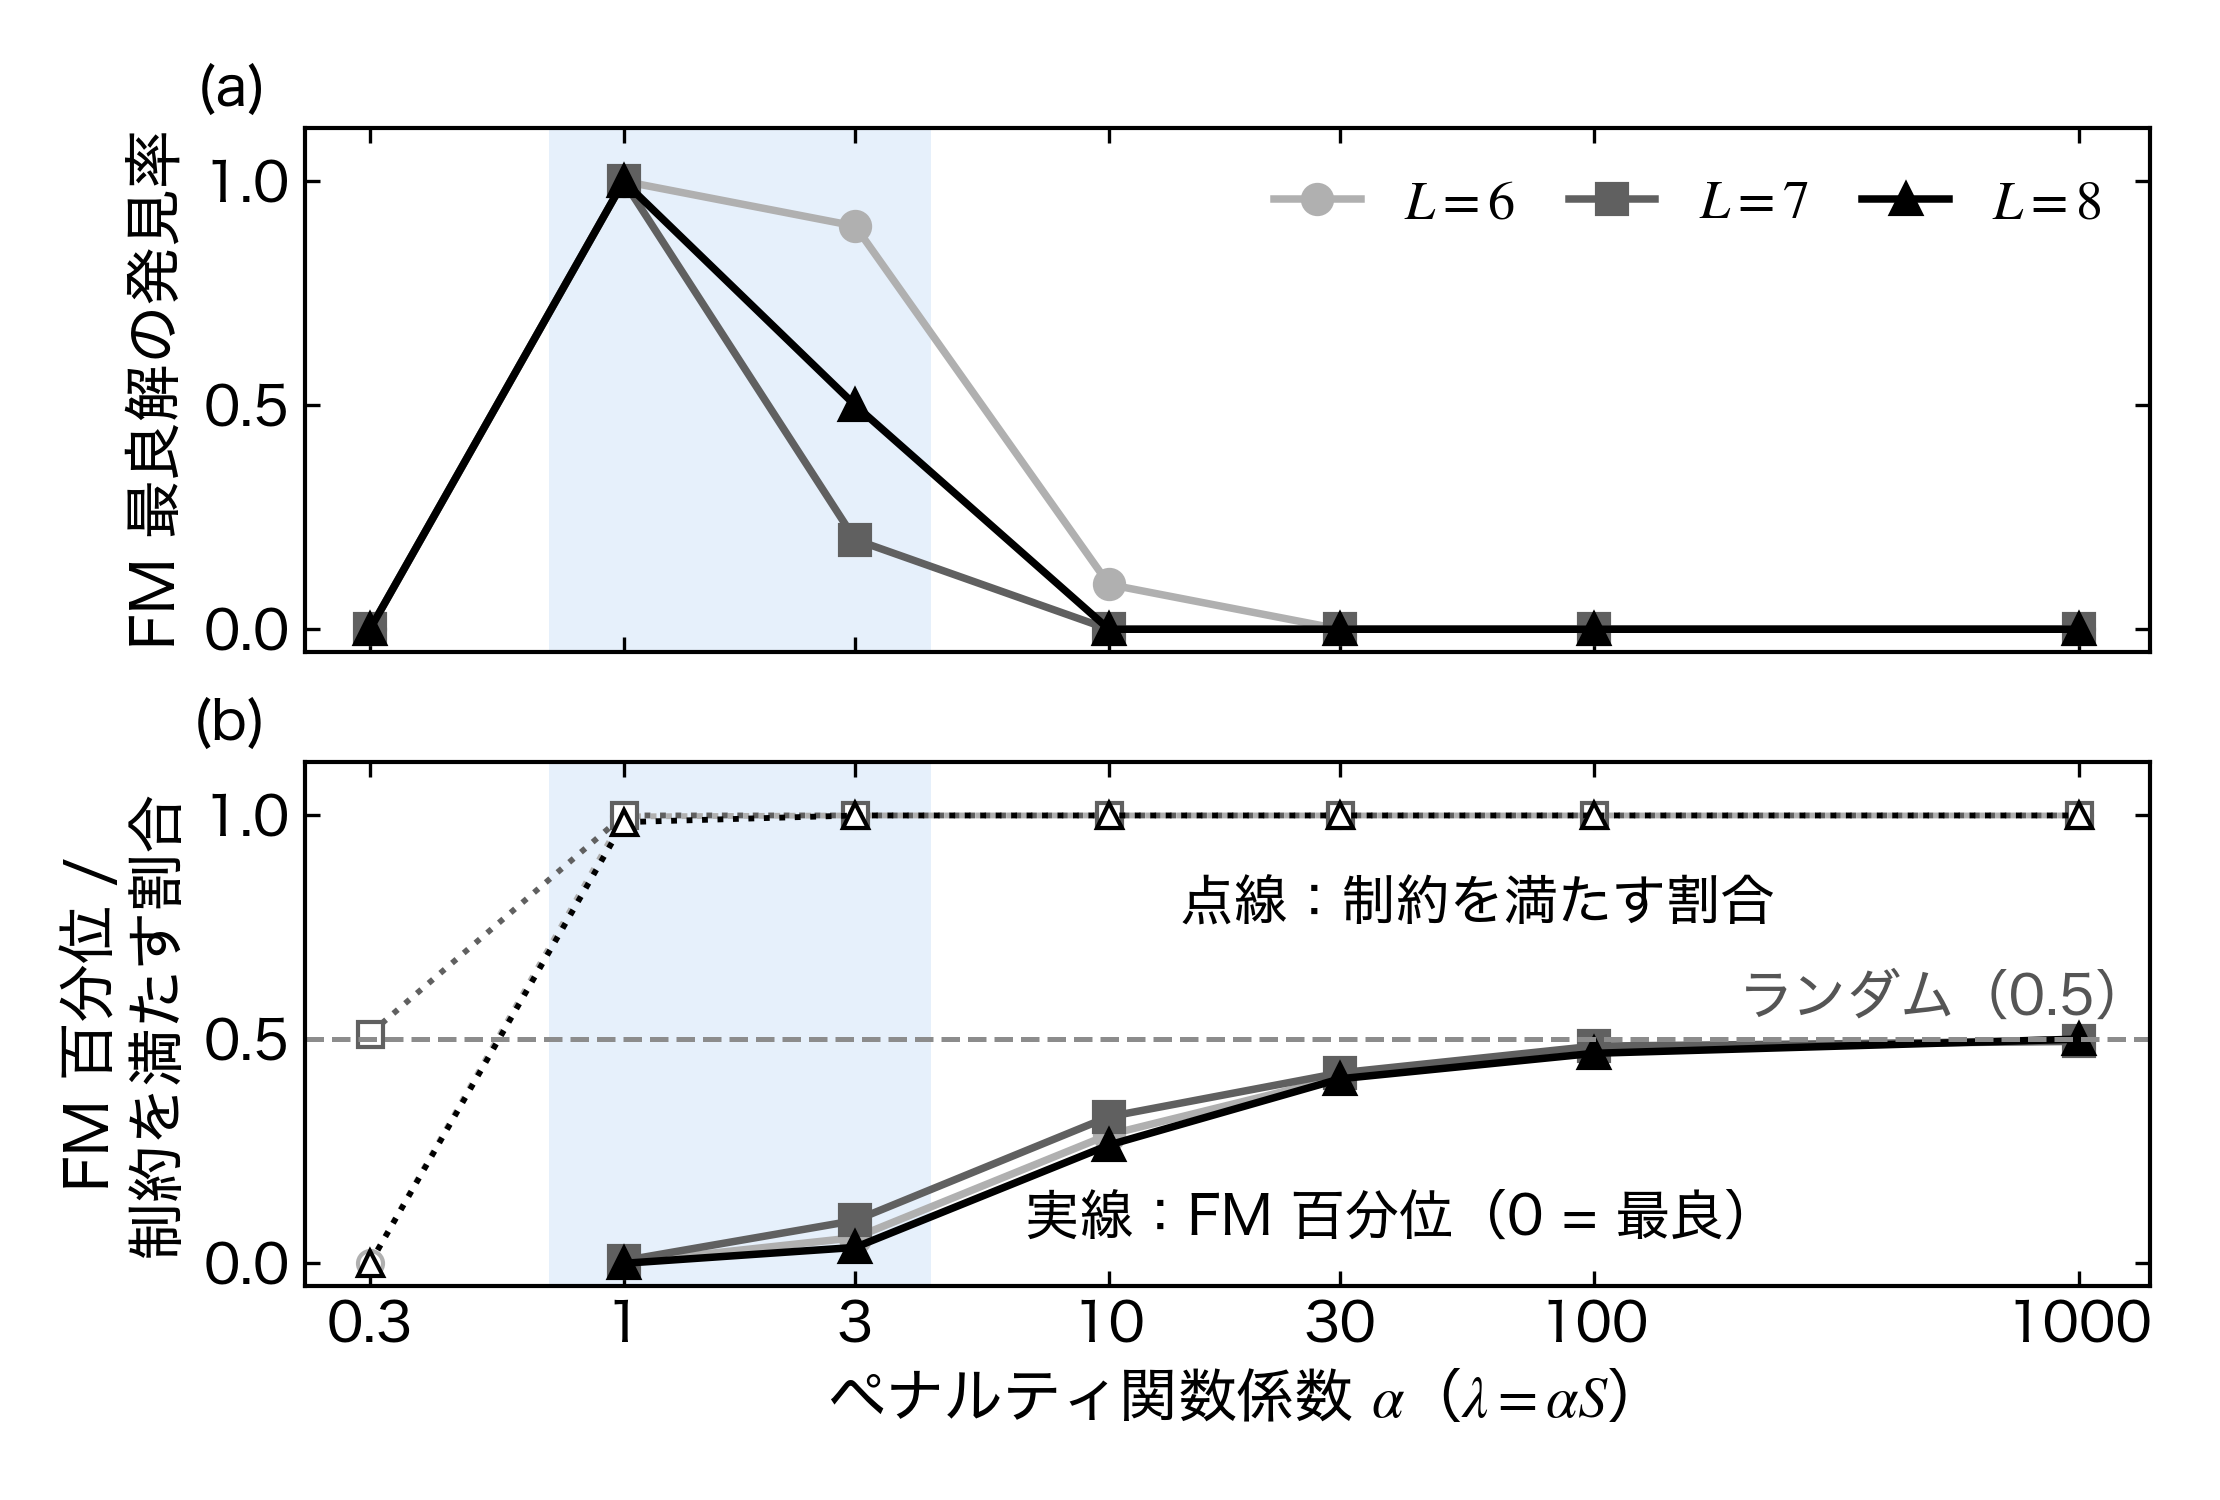

In [4]:
def fig_sweetspot():
    rows = read("slide16_sweetspot.csv")
    with plt.rc_context(JA_RC):
        fig, axes = plt.subplots(2, 1, figsize=(FW, FH), sharex=True)
        shades = {6: ("#b0b0b0", "o"), 7: ("#606060", "s"), 8: ("black", "^")}
        for ax in axes:
            ax.axvspan(0.7, 4.3, color="#e6f0fb", lw=0, zorder=0)
            alpha_axis(ax)
        for L, (c, mk) in shades.items():
            r = [x for x in rows if x["layers"] == L]
            col = lambda k: [np.nan if x[k] is None else x[k] for x in r]
            a = [x["alpha"] for x in r]
            axes[0].plot(a, col("capture_median"), color=c, marker=mk, ms=7, lw=1.8, label=f"$L={L}$")
            axes[1].plot(a, col("sample_fm_pct_median"), color=c, marker=mk, ms=7, lw=1.8)
            axes[1].plot(a, col("feasible_median"), color=c, marker=mk, ms=6, lw=1.4, ls=":", mfc="white")
        axes[0].set_ylabel("FM 最良解の発見率"); axes[0].set_ylim(-0.05, 1.12); axes[0].set_yticks([0, 0.5, 1])
        axes[0].legend(loc="upper right", ncol=3, handlelength=1.6, columnspacing=1.0, fontsize=13)
        axes[1].axhline(0.5, color=GRAY, ls="--", lw=1.2)
        axes[1].text(1400, 0.53, "ランダム（0.5）", ha="right", va="bottom", fontsize=13, color="#555555")
        axes[1].text(40, 0.04, "実線：FM 百分位（0 = 最良）", fontsize=13, va="bottom", ha="center")
        axes[1].text(14, 0.80, "点線：制約を満たす割合", fontsize=13, va="center")
        axes[1].set_ylabel("FM 百分位 /\n制約を満たす割合"); axes[1].set_ylim(-0.05, 1.12); axes[1].set_yticks([0, 0.5, 1])
        axes[1].set_xlabel("ペナルティ関数係数 $\\alpha$（$\\lambda=\\alpha S$）")
        letters(axes)
        fig.tight_layout(h_pad=0.6)
        save(fig, "slide_sweetspot")


fig_sweetspot()

### スライド 17:XY-QAOA の深さと FM ギャップ(固定 FM)

- 何を示すか:XY-FMQAOA(λ=0)が選んだ候補の FM 値が、FM の最小値からどれだけ離れているか。
- 横軸:XY-QAOA の深さ p(1〜6)。縦軸:正規化 FM ギャップ(0 = FM の最良解を選んだ、小さいほど良い)。
- 青線と帯:XY の中央値と四分位範囲(5 個の FM、角度探索 1024 回、CVaR 10%)。横線:SA の各 α とランダム提案の中央値。
- パネル:L = 6, 7, 8(候補数 4,096 / 16,384 / 65,536)。
- 限界:XY は理想的な状態ベクトルのシミュレーション。計算量は SA と揃えていない。

png/slide_depth.png, pdf/slide_depth.pdf


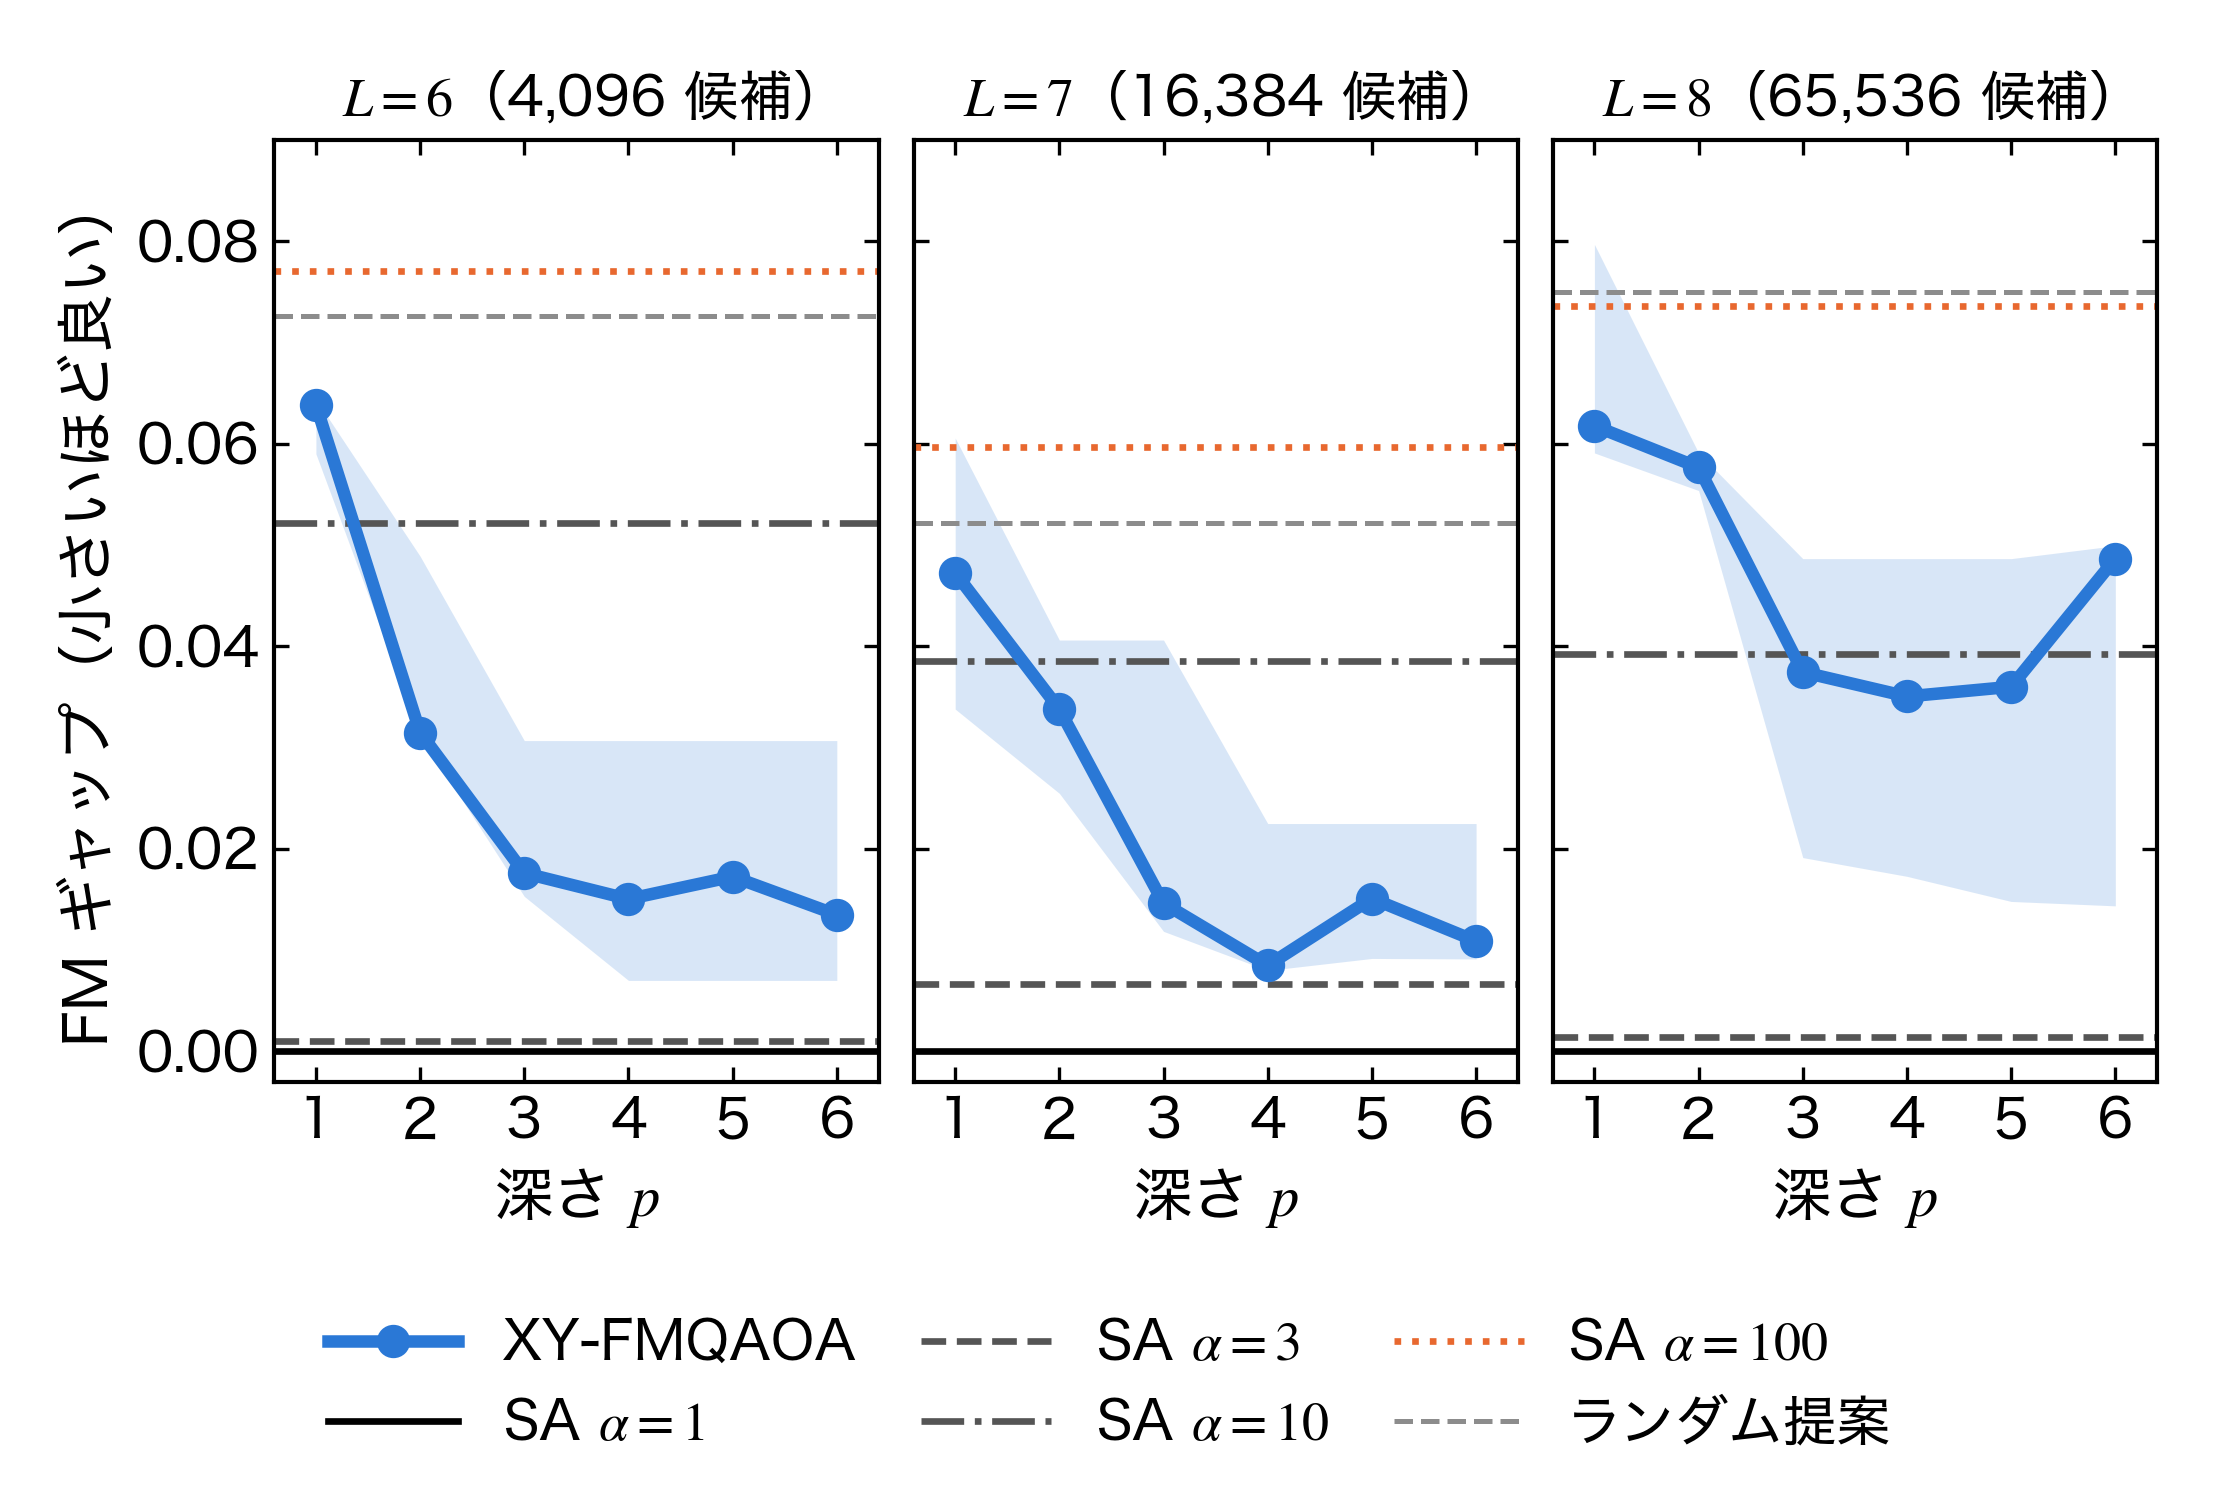

In [5]:
def fig_depth():
    rows = read("slide17_depth.csv")
    ref = {(int(r["layers"]), r["method"]): r["norm_gap_median"] for r in rows if r["method"] != "XY-FMQAOA"}
    with plt.rc_context(JA_RC):
        fig, axes = plt.subplots(1, 3, figsize=(FW, FH), sharey=True)
        refs = [(1, "black", "-", "SA $\\alpha=1$"), (3, "#555555", "--", "SA $\\alpha=3$"), (10, "#555555", "-.", "SA $\\alpha=10$"),
                (100, ORANGE, ":", "SA $\\alpha=100$")]
        for ax, L in zip(axes, (6, 7, 8)):
            for a, c, ls, lab in refs:
                ax.axhline(ref[(L, f"SA-a{a}")], color=c, ls=ls, lw=1.6, label=lab)
            ax.axhline(ref[(L, "RandomFM")], color=GRAY, ls="--", lw=1.2, label="ランダム提案")
            xy = sorted((r for r in rows if r["layers"] == L and r["method"] == "XY-FMQAOA"), key=lambda r: r["p"])
            p = np.array([r["p"] for r in xy])
            ax.fill_between(p, [r["norm_gap_q25"] for r in xy], [r["norm_gap_q75"] for r in xy], color=BLUE, alpha=0.18, lw=0)
            ax.plot(p, [r["norm_gap_median"] for r in xy], color=BLUE, lw=3.0, marker="o", ms=7, label="XY-FMQAOA")
            ax.set_xticks(p); ax.set_xlim(0.6, 6.4); ax.set_ylim(-0.003, 0.09)
            ax.set_title(f"$L={L}$（{NCAND[L]} 候補）", fontsize=13)
            ax.set_xlabel("深さ $p$")
        axes[0].set_ylabel("FM ギャップ（小さいほど良い）")
        h, l = axes[0].get_legend_handles_labels()
        order = [5, 0, 1, 2, 3, 4]
        fig.legend([h[i] for i in order], [l[i] for i in order], loc="lower center", ncol=3, fontsize=13, handlelength=2.4, columnspacing=1.2)
        fig.tight_layout(rect=(0, 0.13, 1, 1), w_pad=0.6)
        save(fig, "slide_depth")


fig_depth()

### スライド 18:閉ループでの α 掃引(L=7、15 Seed)

- 何を示すか:FMQA を 100 回評価まで回したとき、見つけた最良解の真の順位(1 = 最適解、小さいほど良い)。
- 横軸:SA の α(対数)。黒線 = SA の中央値、灰の帯 = SA の四分位範囲。青の横線 = XY-FMQAOA の中央値、灰破線 = ランダム提案 + FM 選択の中央値。
- 上の数字:最適解に到達した Seed 数(15 中)。集計単位は Seed(同じ 15 Seed を全条件で使用)。
- 限界:α の掃引は事前登録の検定とは別の探索的解析。`Adaptive`(α の自動調整)は CSV にだけ入れて図には描かない。

fsSelection bit 5 (bold) and head table macStyle bit 0 (bold) should match


png/slide_loop_alpha.png, pdf/slide_loop_alpha.pdf


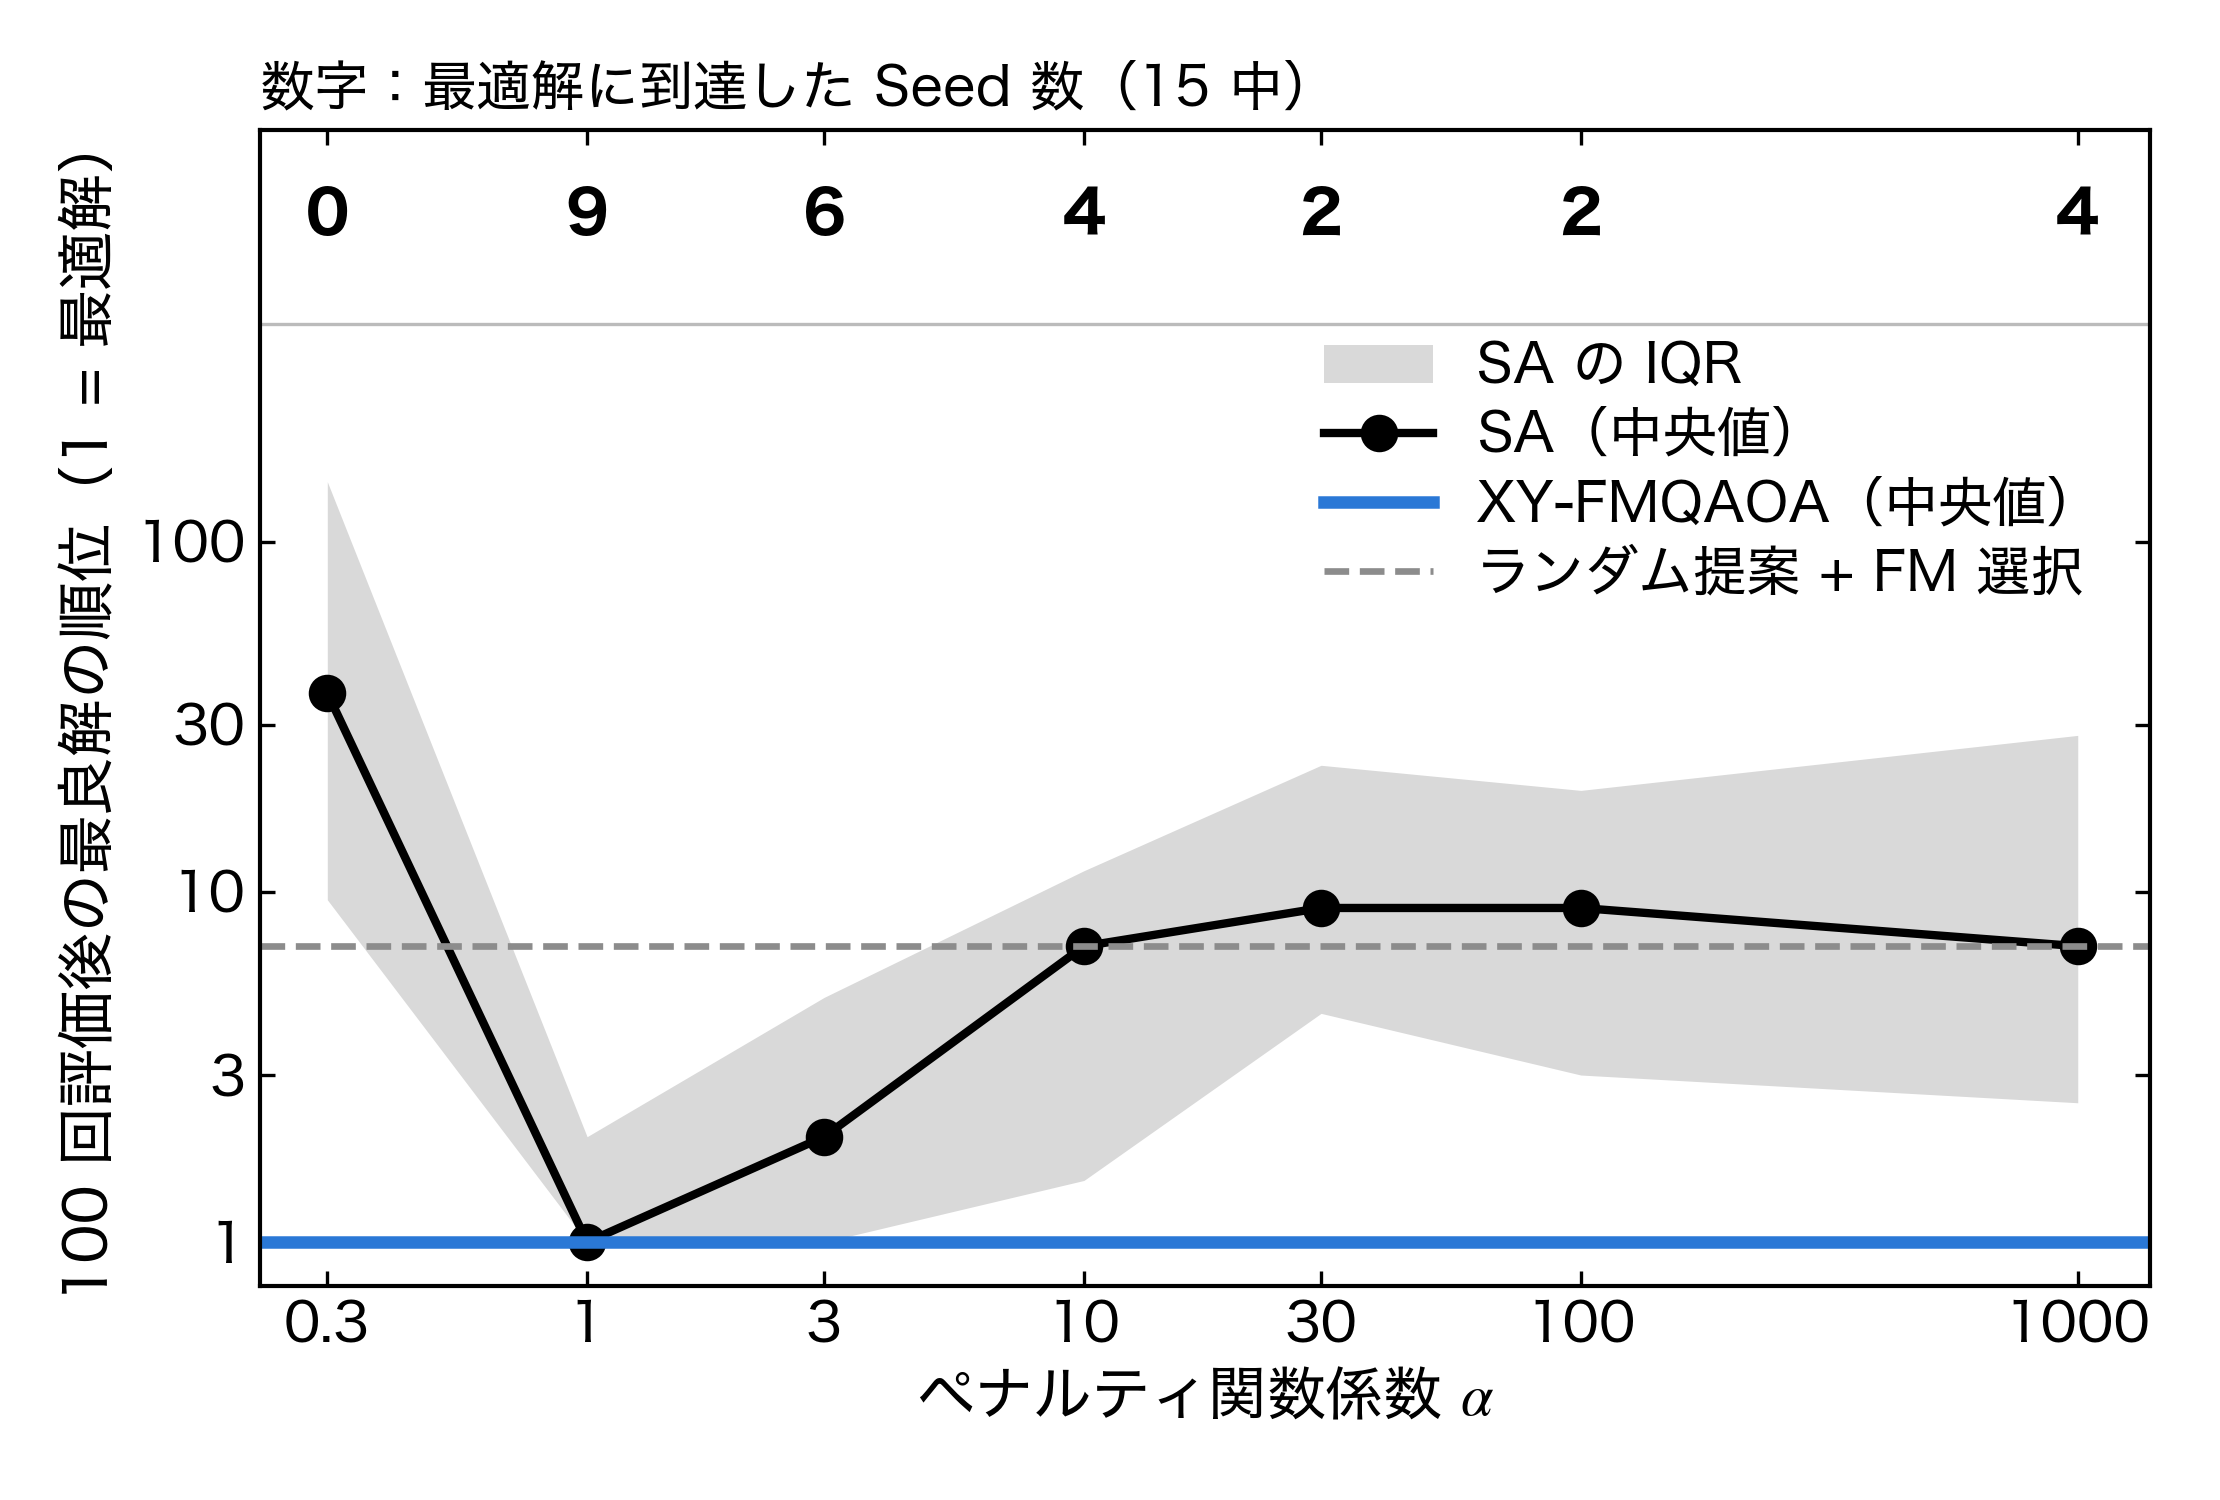

In [6]:
def fig_loop_alpha():
    rows = read("slide18_loop_alpha.csv")
    by = {r["condition"]: r for r in rows}
    sa = [by[f"alpha{num(a)}"] for a in ALPHAS]
    with plt.rc_context(JA_RC):
        fig, ax = plt.subplots(figsize=(FW, FH))
        ax.fill_between(ALPHAS, [r["best_rank_q25"] for r in sa], [r["best_rank_q75"] for r in sa], color="#d9d9d9", lw=0, label="SA の IQR")
        ax.plot(ALPHAS, [r["best_rank_median"] for r in sa], color="black", marker="o", ms=8, lw=2.0, label="SA（中央値）")
        ax.axhline(by["XY-FMQAOA"]["best_rank_median"], color=BLUE, lw=3.0, label="XY-FMQAOA（中央値）")
        ax.axhline(by["RandomFM"]["best_rank_median"], color=GRAY, ls="--", lw=1.6, label="ランダム提案 + FM 選択")
        ax.set_yscale("log"); ax.set_ylim(0.75, 1500); log_ticks(ax.yaxis, [1, 3, 10, 30, 100])
        alpha_axis(ax)
        ax.set_xlabel("ペナルティ関数係数 $\\alpha$"); ax.set_ylabel("100 回評価後の最良解の順位（1 = 最適解）")
        for a, r in zip(ALPHAS, sa):
            ax.text(a, 850, f"{int(r['n_optimum'])}", ha="center", va="center", fontsize=14, fontweight="bold")
        ax.axhline(420, color="#bbbbbb", lw=0.8)
        ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.86), fontsize=13, labelspacing=0.3)
        ax.set_title("数字：最適解に到達した Seed 数（15 中）", fontsize=13, loc="left")
        fig.tight_layout()
        save(fig, "slide_loop_alpha")


fig_loop_alpha()

### スライド 19:第 2 確認実験の推移(L=7、独立な 30 Seed)

- 何を示すか:評価回数が増えるにつれて、見つけた最良解がどう良くなるか。
- 横軸:評価回数(初期 40 点 + 提案 60 回、上下で共通)。(a) 縦軸:最良解の真の順位の中央値(対数、小さいほど良い)。(b) 縦軸:最適解に到達した Seed の割合(大きいほど良い)。
- 線:XY-FMQAOA 青実線、SA α=1 黒破線、カテゴリ型 SA 紫点線、SA α=100 橙、SA α=0.3 緑一点鎖線。集計単位は Seed。
- 100 回時点の到達数(XY 23、α=1 18、カテゴリ型 SA 16、α=100 4、α=0.3 2)は `confirm2_final.csv` と一致する。
- 限界:問題は 1 種類。`Boltzmann-t0.2` は元 CSV にあるが図には出さない。

png/slide_confirm2.png, pdf/slide_confirm2.pdf


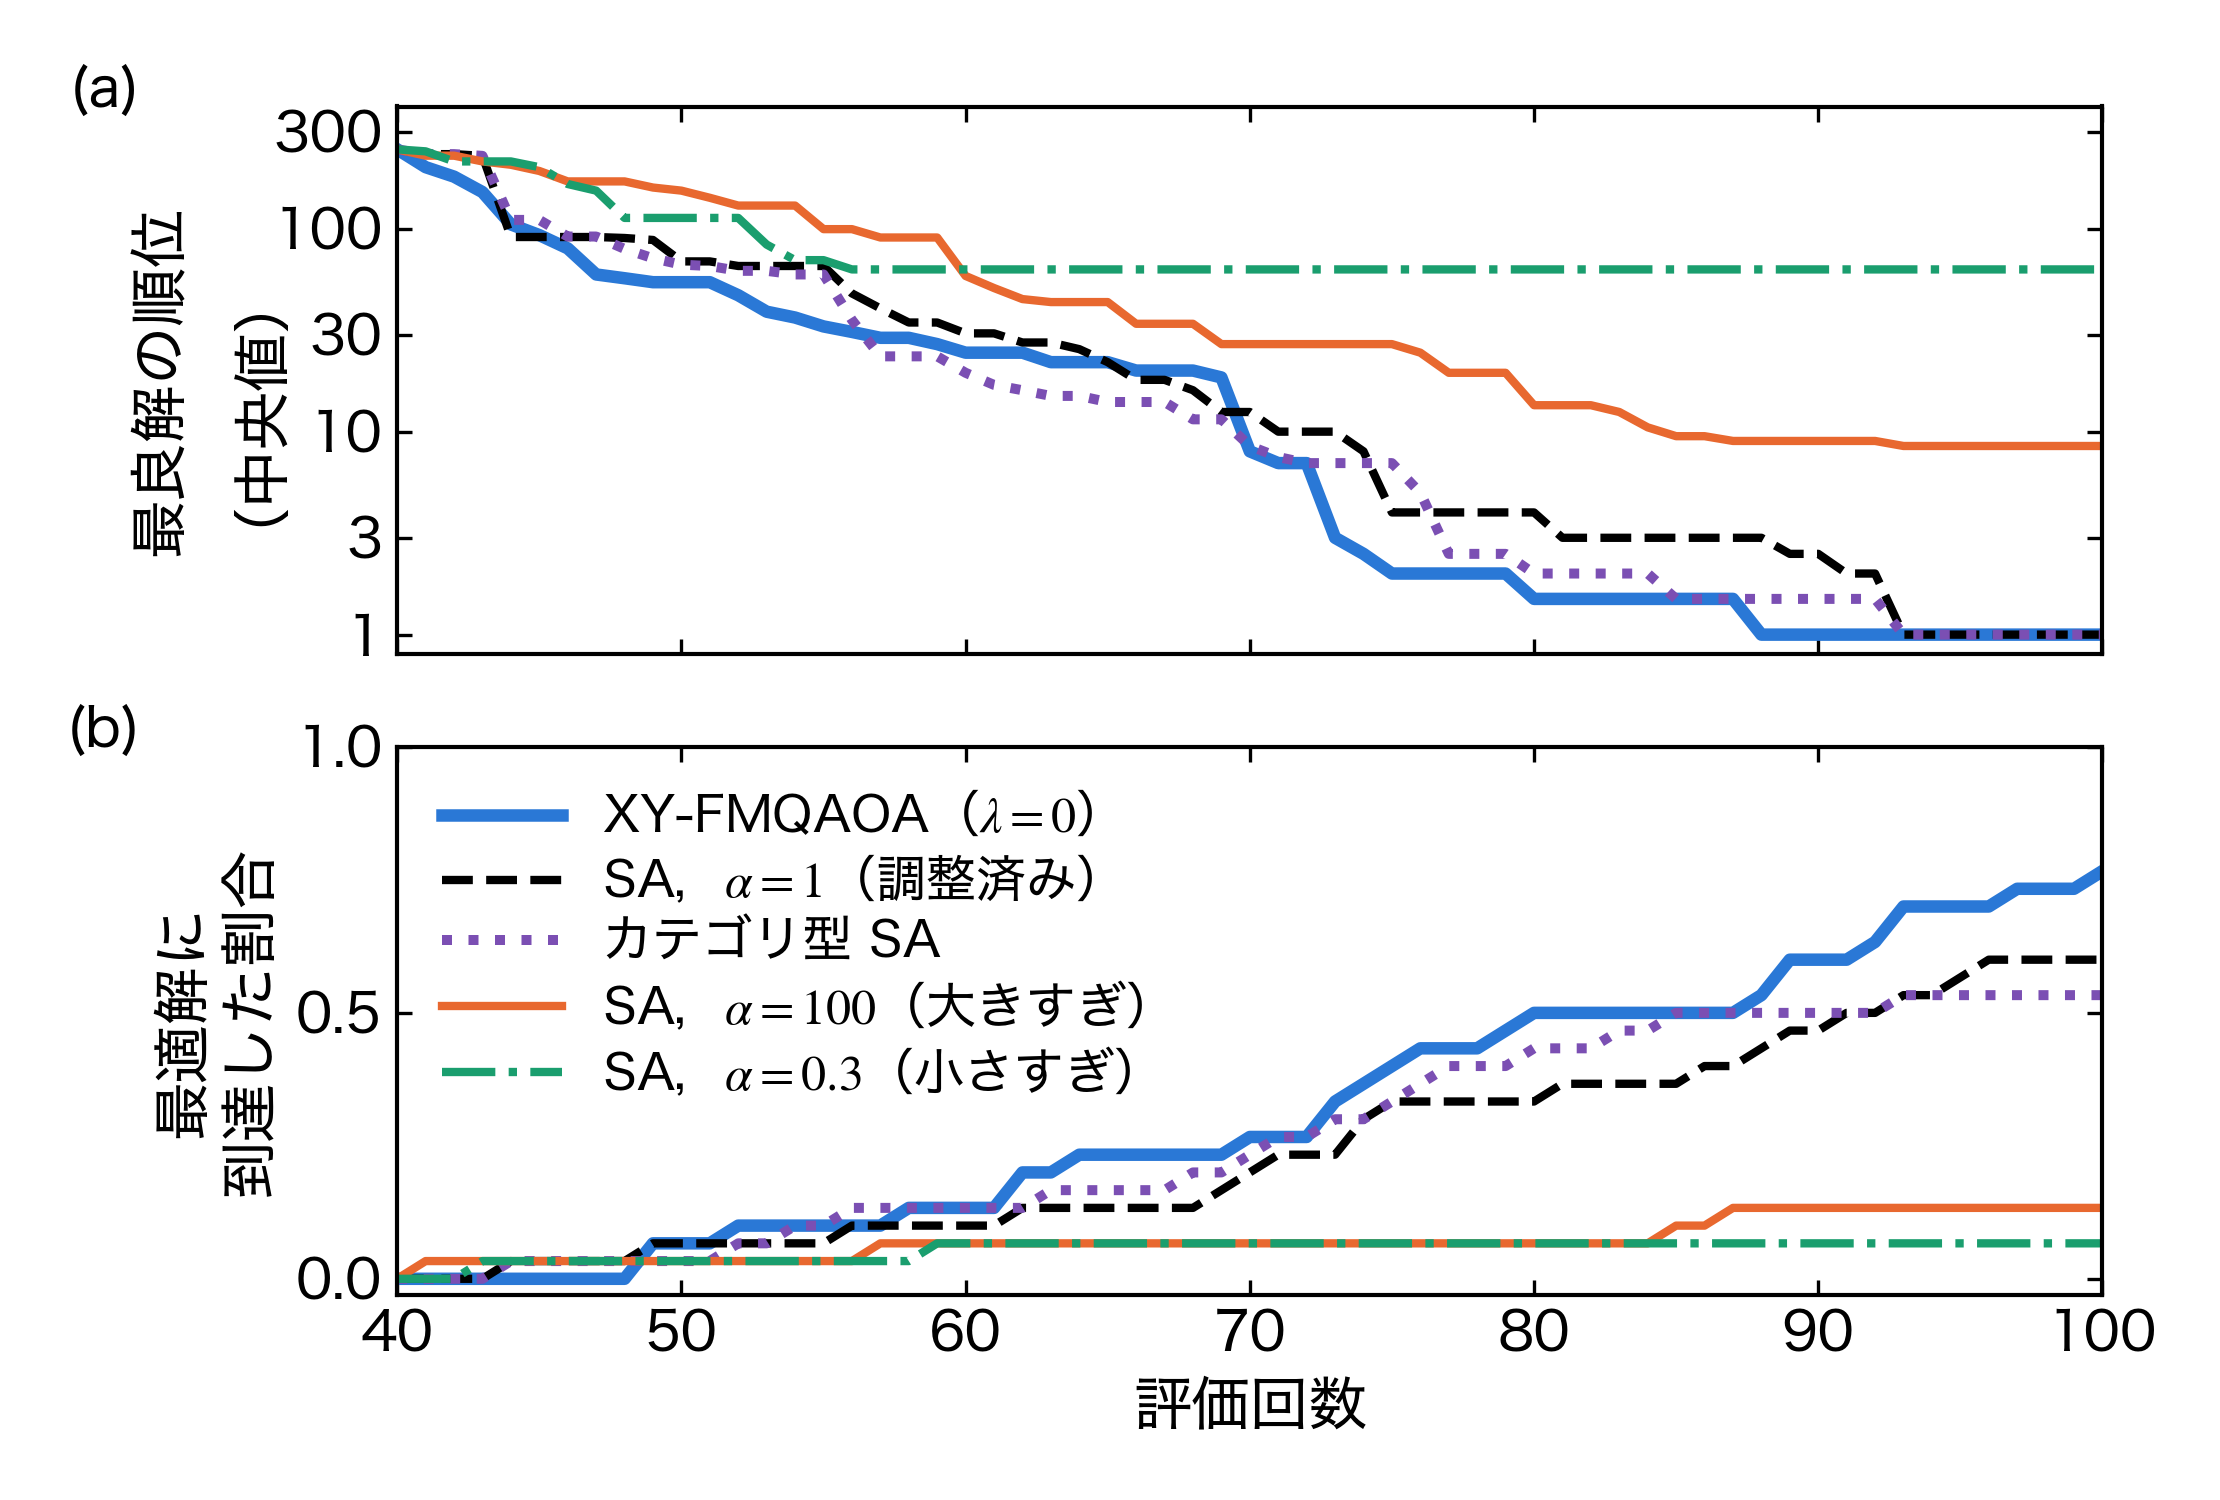

In [7]:
def fig_confirm2():
    rows = read("slide19_confirm2.csv")
    conds = ["XY-FMQAOA", "alpha1", "CatSA", "alpha100", "alpha0.3"]
    with plt.rc_context(JA_RC):
        fig, axes = plt.subplots(2, 1, figsize=(FW, FH), sharex=True)
        for c in conds:
            r = sorted((x for x in rows if x["condition"] == c), key=lambda x: x["evaluations"])
            E = [x["evaluations"] for x in r]
            st = {k: M[c][k] for k in ("color", "ls", "lw")}
            axes[0].plot(E, [x["best_rank_median"] for x in r], **st, label=M[c]["label"])
            axes[1].plot(E, [x["frac_optimum"] for x in r], **st)
        axes[0].set_yscale("log"); axes[0].set_ylim(0.8, 400); log_ticks(axes[0].yaxis, [1, 3, 10, 30, 100, 300])
        axes[0].set_ylabel("最良解の順位\n（中央値）")
        axes[1].set_ylim(-0.03, 1.0); axes[1].set_yticks([0, 0.5, 1]); axes[1].set_ylabel("最適解に\n到達した割合"); axes[1].set_xlabel("評価回数")
        axes[1].set_xlim(40, 100)
        h, l = axes[0].get_legend_handles_labels()
        axes[1].legend(h, l, loc="upper left", fontsize=12, handlelength=2.4, labelspacing=0.25)
        letters(axes, x=-0.15, y=0.98)
        fig.tight_layout(h_pad=0.6)
        save(fig, "slide_confirm2")


fig_confirm2()

### スライド 21:実行可能なサンプルの FM 百分位の分布(固定 FM、L=7)

- 何を示すか:各提案器が出す実行可能なサンプルが、FM の値でどのあたりに分布するか。
- 横軸:サンプルの FM 百分位(0 = FM 最良、1 = 最悪、幅 0.05 のビン)。縦軸:密度(対数)。一様ランダムなら密度 1 で平ら。
- 線:SA α=1 黒、α=10 灰一点鎖線、α=100 橙、XY-FMQAOA p=4 青、ランダム提案 灰破線。5 個の FM × 10 回の繰り返しを合算。
- 左側(0 付近)の密度が高いほど、FM の良い解を多く出している。α を大きくすると一様ランダムに近づく。
- 限界:分布の形と閉ループ性能の因果は未検証。

png/slide_energy_hist.png, pdf/slide_energy_hist.pdf


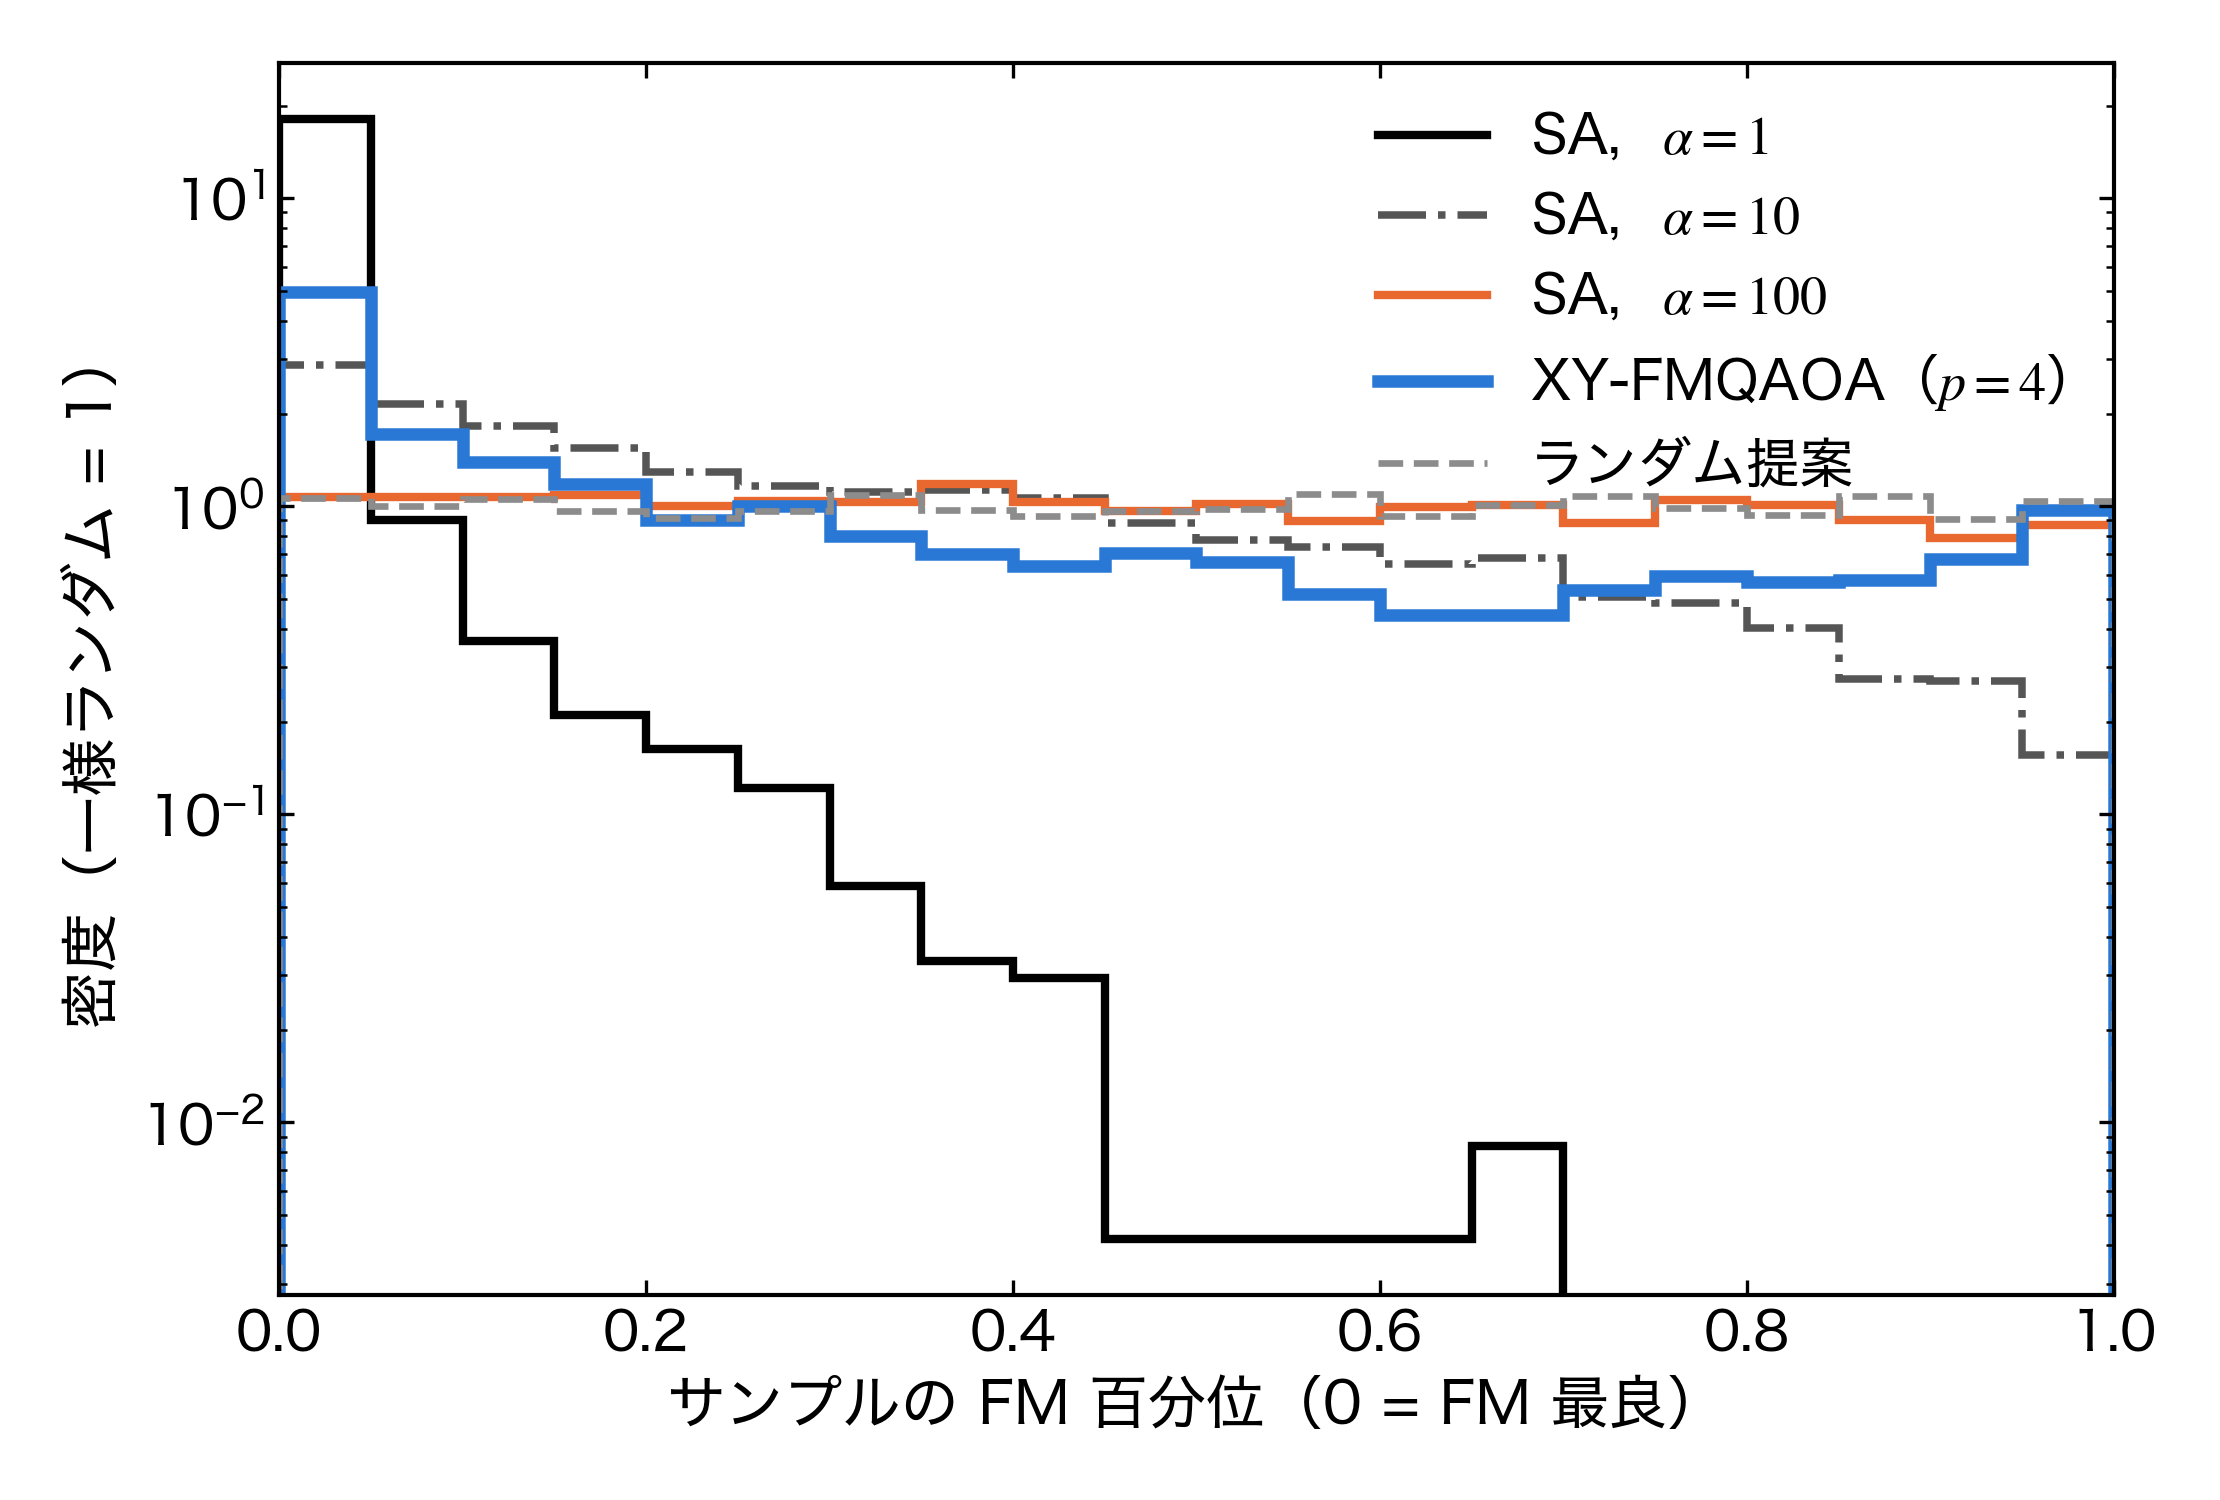

In [8]:
def fig_energy_hist():
    rows = read("slide21_energy_hist.csv")
    samplers = [("SA-auto-a1", "SA，$\\alpha=1$", dict(color="black", ls="-", lw=2.0)),
                ("SA-auto-a10", "SA，$\\alpha=10$", dict(color="#555555", ls="-.", lw=1.8)),
                ("SA-auto-a100", "SA，$\\alpha=100$", dict(color=ORANGE, ls="-", lw=2.0)),
                ("XY-p4-cvar10", "XY-FMQAOA（$p=4$）", dict(color=BLUE, ls="-", lw=3.0)),
                ("RandomFM", "ランダム提案", dict(color=GRAY, ls="--", lw=1.6))]
    with plt.rc_context(JA_RC):
        fig, ax = plt.subplots(figsize=(FW, FH))
        for key, lab, st in samplers:
            r = sorted((x for x in rows if x["sampler"] == key), key=lambda x: x["bin_lo"])
            edges = np.append([x["bin_lo"] for x in r], 1.0)
            ax.stairs([x["density"] for x in r], edges, label=lab, **st)
        ax.set_yscale("log"); ax.set_xlim(0, 1)
        ax.set_xlabel("サンプルの FM 百分位（0 = FM 最良）"); ax.set_ylabel("密度（一様ランダム = 1）")
        ax.legend(loc="upper right", fontsize=13)
        fig.tight_layout()
        save(fig, "slide_energy_hist")


fig_energy_hist()

### スライド 22:温度を再設定しても平準化は残る

- (a)〜(c) 固定 FM(L = 6, 7, 8):横軸 α(対数)、縦軸 サンプルの FM 百分位の平均(0 = FM 最良、0.5 = ランダム、小さいほど良い)。
  線は SA の温度設定:自動(1000 sweeps)黒丸、FM 規模に合わせた温度範囲 橙四角、自動で 10 倍の sweeps 緑三角、FM 規模 + 10 倍 紫菱形。
  灰破線 = ランダム提案、青の太線 = XY-FMQAOA p=4。値は 5 個の FM の中央値。
- (d) 閉ループ(L=7、15 Seed):100 回評価後の最良解の順位(対数)。点 = Seed(横方向のずれは重なりを避けるための固定乱数)、横棒 = 中央値。
- 限界:事前登録の検定とは別の探索的解析。

png/slide_retune_robustness.png, pdf/slide_retune_robustness.pdf


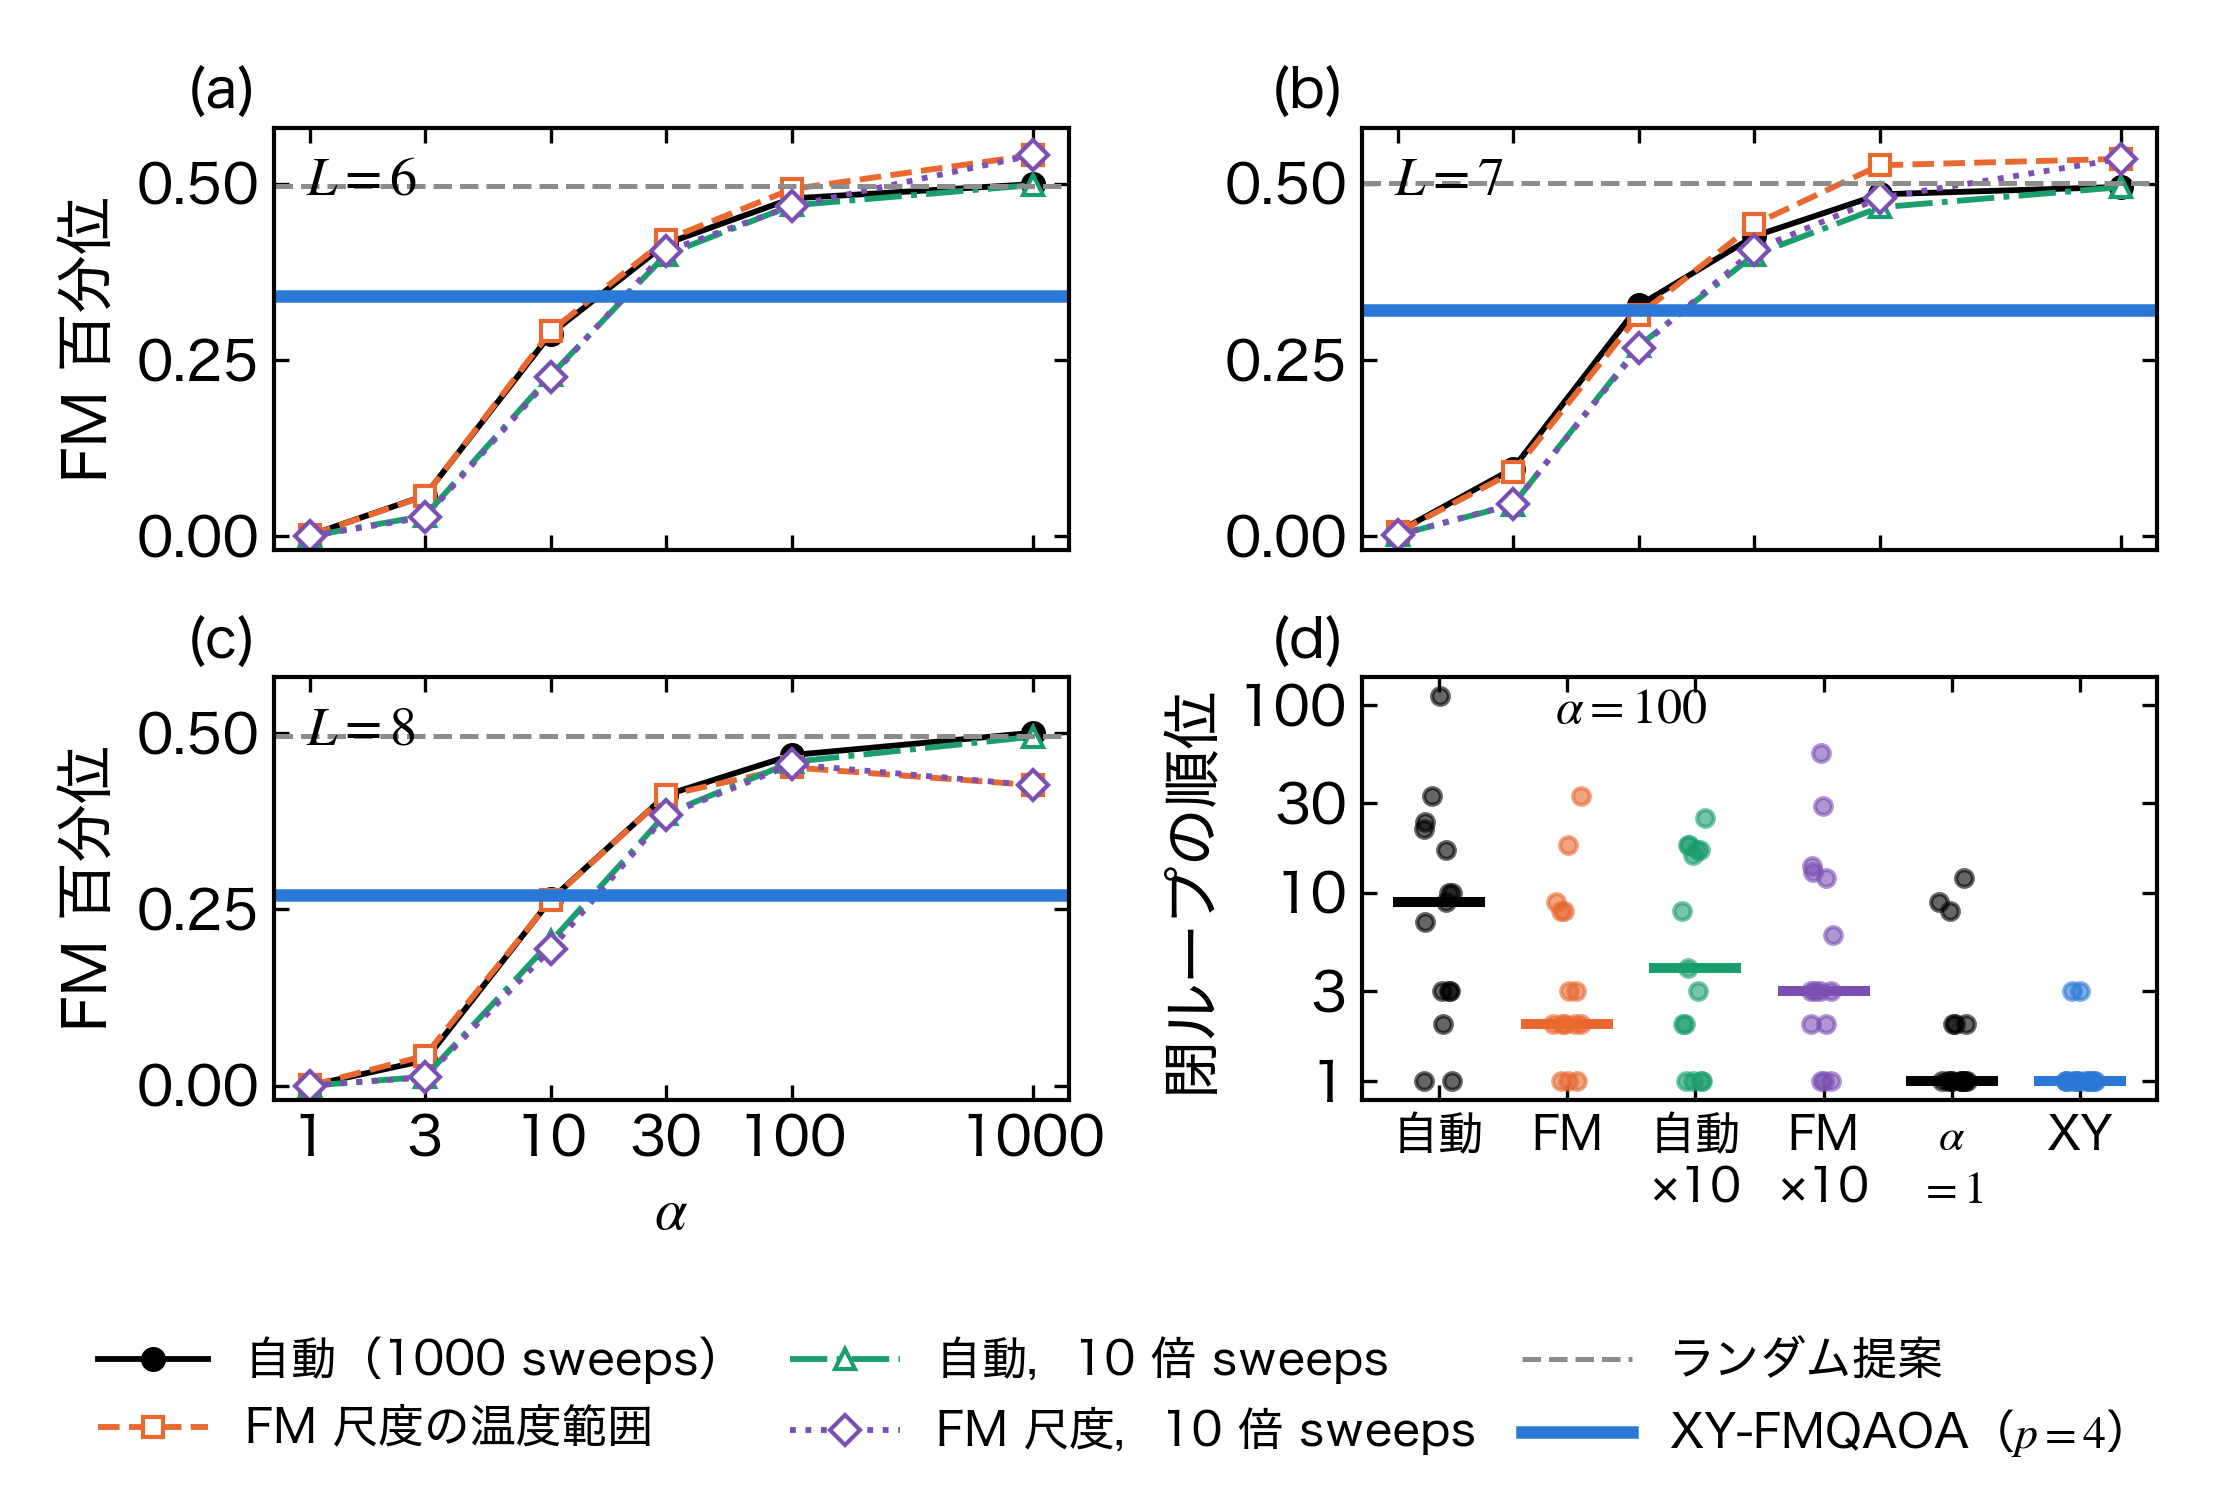

In [9]:
SCHEDULE_STYLE = {"auto": dict(color="black", ls="-", marker="o"), "fmscale": dict(color=ORANGE, ls="--", marker="s", mfc="white"),
                  "wide10x": dict(color=GREEN, ls="-.", marker="^", mfc="white"), "fmscale10x": dict(color=PURPLE, ls=":", marker="D", mfc="white")}
SCHEDULE_LABEL = {"auto": "自動（1000 sweeps）", "fmscale": "FM 尺度の温度範囲", "wide10x": "自動，10 倍 sweeps", "fmscale10x": "FM 尺度，10 倍 sweeps"}


def fig_retune():
    rows = read("slide22_retune_fixedfm.csv")
    loop = read("slide22_retune_loop.csv")
    alphas = [1, 3, 10, 30, 100, 1000]
    with plt.rc_context(JA_RC):
        fig, axes = plt.subplots(2, 2, figsize=(FW, FH))
        axes = axes.ravel()
        for ax, L in zip(axes[:3], (6, 7, 8)):
            for sch, st in SCHEDULE_STYLE.items():
                r = {x["alpha"]: x["sample_fm_pct_median"] for x in rows if x["layers"] == L and x["series"] == f"SA-{sch}"}
                ax.plot(alphas, [np.nan if r[a] is None else r[a] for a in alphas], label=SCHEDULE_LABEL[sch], ms=5, lw=1.4, **st)
            ref = {x["series"]: x["sample_fm_pct_median"] for x in rows if x["layers"] == L and x["alpha"] is None}
            ax.axhline(ref["RandomFM"], color=GRAY, ls="--", lw=1.2, label="ランダム提案")
            ax.axhline(ref["XY-p4-cvar10"], color=BLUE, lw=3.0, label="XY-FMQAOA（$p=4$）")
            ax.set_xscale("log"); log_ticks(ax.xaxis, alphas); ax.set_ylim(-0.02, 0.58); ax.set_yticks([0, 0.25, 0.5])
            ax.text(0.04, 0.94, f"$L={L}$", transform=ax.transAxes, ha="left", va="top", fontsize=13)
        for ax in axes[:2]:
            ax.tick_params(labelbottom=False)
        axes[2].set_xlabel("$\\alpha$")
        axes[0].set_ylabel("FM 百分位"); axes[2].set_ylabel("FM 百分位")
        conds = [("alpha100", "auto"), ("alpha100-fmscale", "fmscale"), ("alpha100-wide10x", "wide10x"),
                 ("alpha100-fmscale10x", "fmscale10x"), ("alpha1", None), ("XY-FMQAOA", None)]
        ax = axes[3]
        for i, (c, sch) in enumerate(conds):
            v = [r["best_rank"] for r in loop if r["condition"] == c]
            col = SCHEDULE_STYLE[sch]["color"] if sch else M[c]["color"]
            ax.plot([i] * len(v) + 0.12 * np.random.default_rng(i).uniform(-1, 1, len(v)), v, "o", ms=4, color=col, alpha=0.6)
            ax.plot([i - 0.32, i + 0.32], [np.median(v)] * 2, color=col, lw=2.4)
        ax.set_xticks(range(len(conds))); ax.set_xticklabels(["自動", "FM", "自動\n×10", "FM\n×10", "$\\alpha$\n$=1$", "XY"], fontsize=11)
        ax.set_yscale("log"); log_ticks(ax.yaxis, [1, 3, 10, 30, 100]); ax.set_ylabel("閉ループの順位")
        ax.text(1.5, 0.98, "$\\alpha=100$", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=12)
        letters(axes)
        h, l = axes[0].get_legend_handles_labels()
        fig.legend(h, l, loc="lower center", ncol=3, fontsize=11, handlelength=2.4, columnspacing=1.0)
        fig.tight_layout(rect=(0, 0.13, 1, 1), h_pad=0.8, w_pad=1.0)
        save(fig, "slide_retune_robustness")


fig_retune()

### スライド 23:第 1 確認実験の Seed ごとの対応(L=7、15 Seed)

- 何を示すか:同じ Seed(同じ初期データ)で、比較手法と XY-FMQAOA の 100 回評価後の最良解の順位を線で結ぶ。
- 縦軸:最良解の真の順位(対数、1 = 最適解、小さいほど良い)。左の点 = 比較手法、右の点 = XY。
- 色:青 = XY が良い、橙 = XY が悪い、灰 = 同じ順位。パネル上の数字はその内訳。
- パネル:(a) SA α=0.3、(b) SA α=100、(c) SA α=1。事前登録した片側 Wilcoxon 検定(Bonferroni 補正)は (a)(b) が主検定、(c) は参考。
- 限界:問題は 1 種類、Seed は 15 個。

png/slide_paired_ranks.png, pdf/slide_paired_ranks.pdf


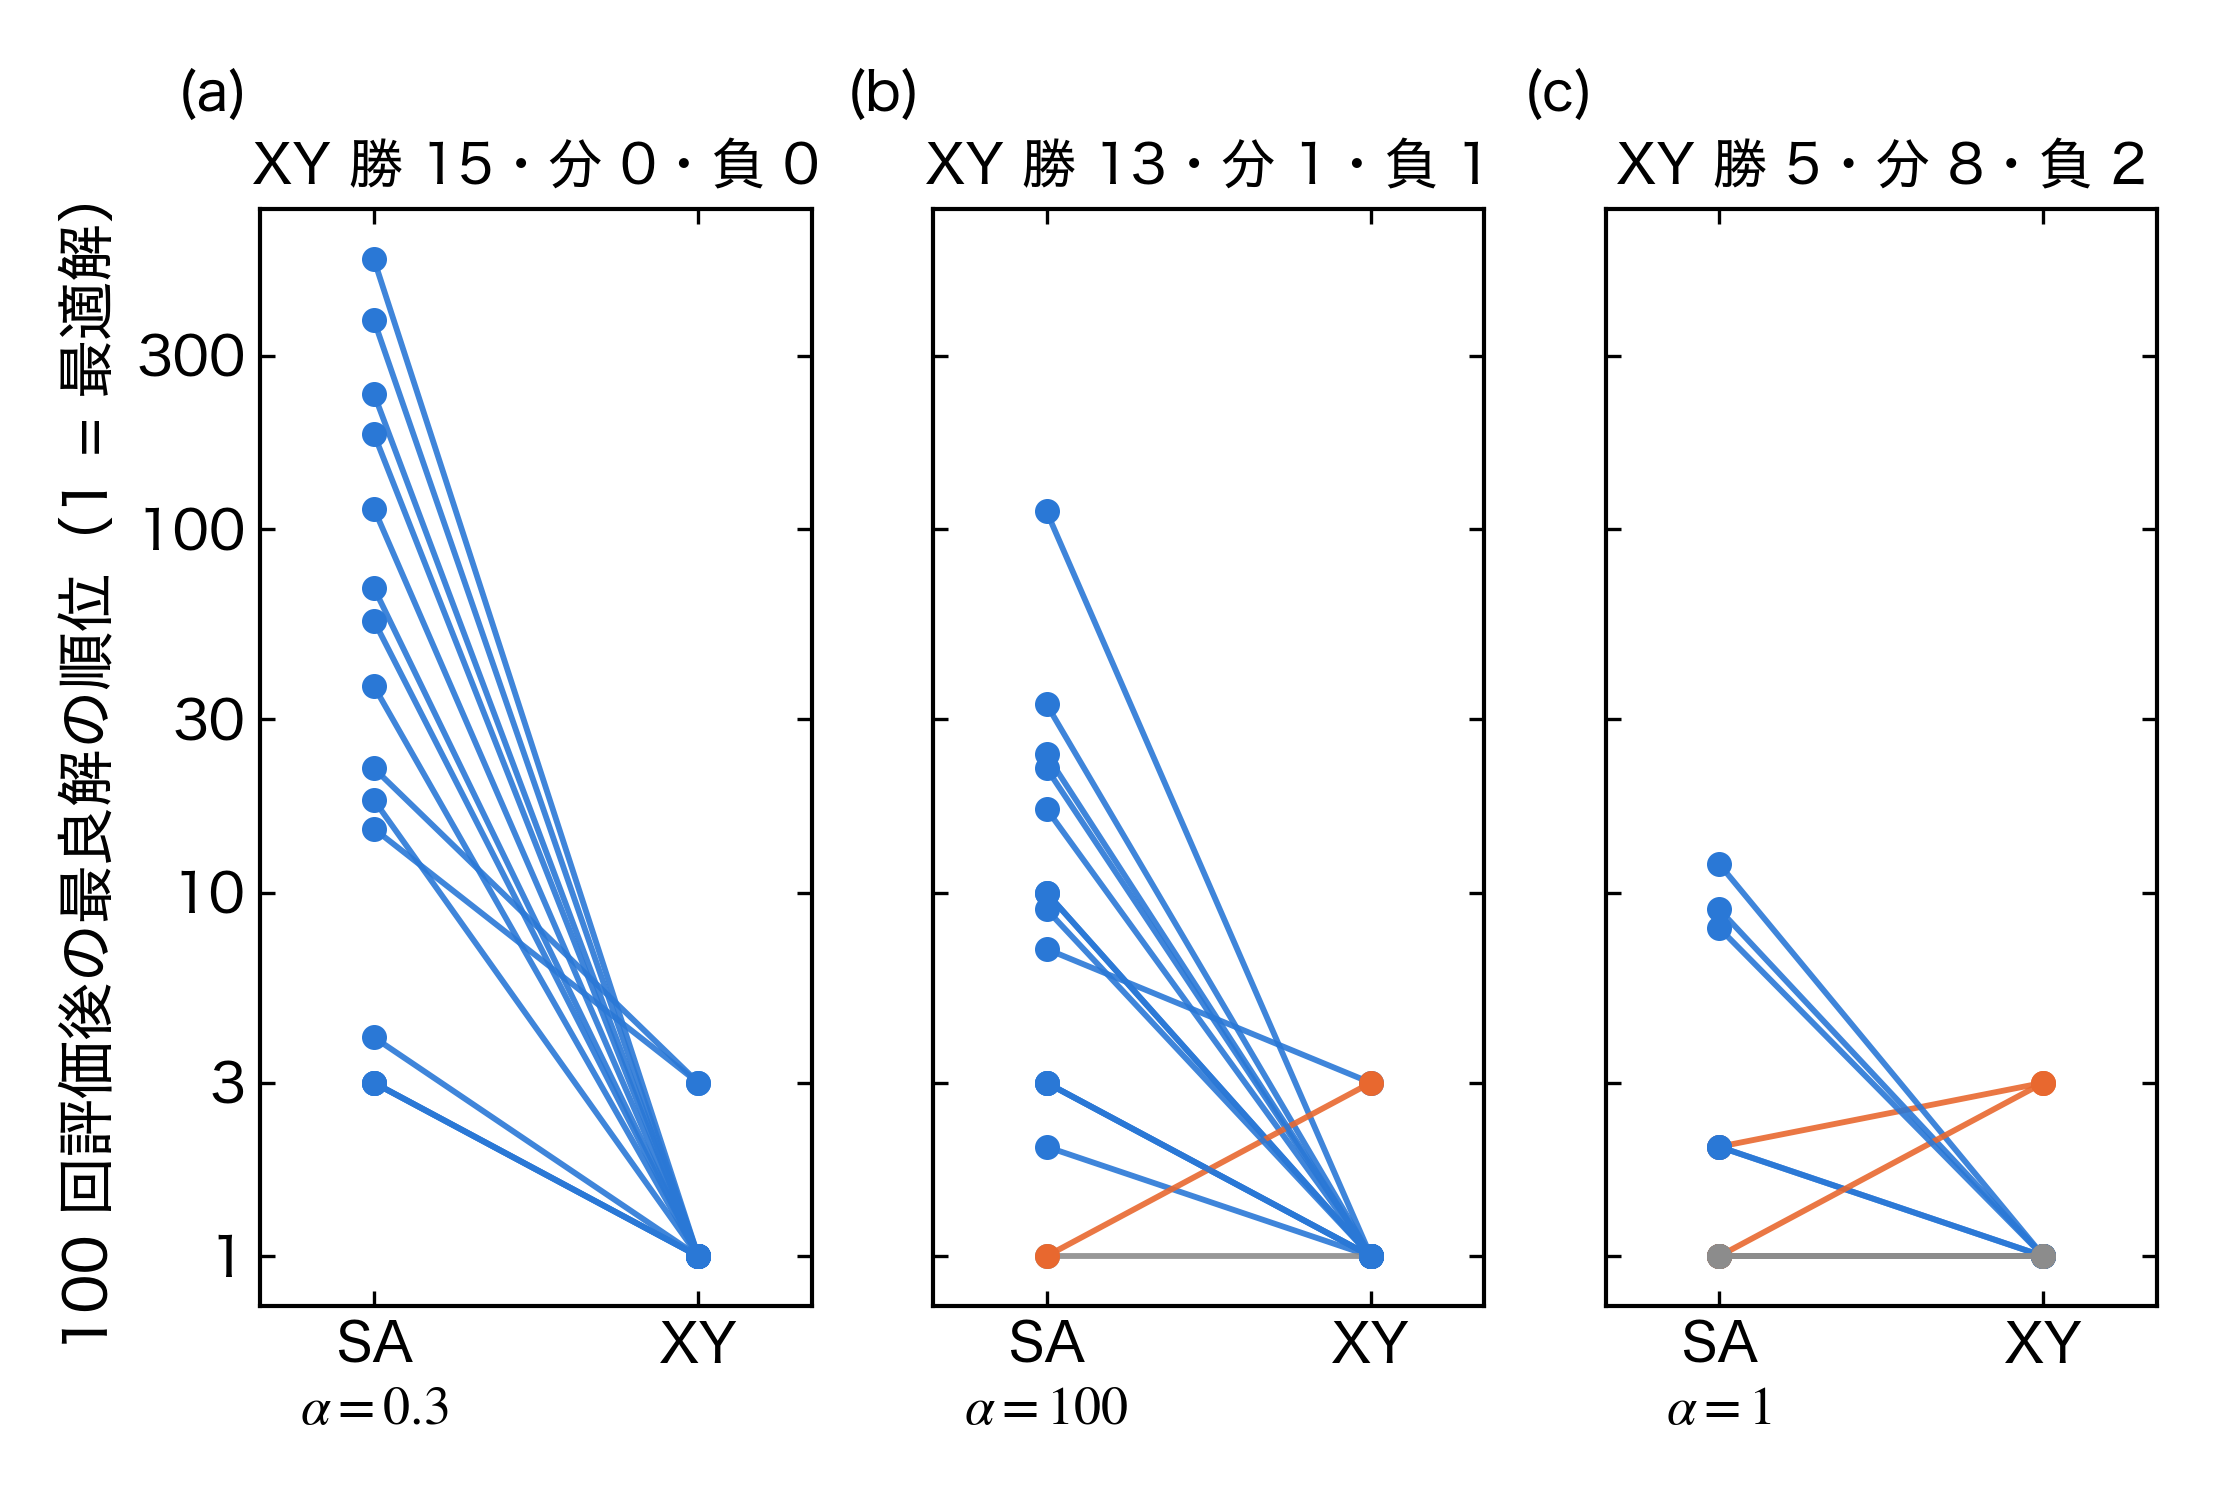

In [10]:
CMP_LABEL = {"alpha0.3": "SA\n$\\alpha=0.3$", "alpha100": "SA\n$\\alpha=100$", "alpha1": "SA\n$\\alpha=1$"}


def fig_paired():
    rows = read("slide23_paired_ranks.csv")
    color = {"xy_better": BLUE, "tie": GRAY, "xy_worse": ORANGE}
    with plt.rc_context(JA_RC):
        fig, axes = plt.subplots(1, 3, figsize=(FW, FH), sharey=True)
        for ax, c in zip(axes, ("alpha0.3", "alpha100", "alpha1")):
            r = sorted((x for x in rows if x["comparator"] == c), key=lambda x: x["seed"])
            for x in r:
                col = color[x["outcome"]]
                ax.plot([0, 1], [x["comparator_rank"], x["xy_rank"]], "-", color=col, lw=1.4, alpha=0.9)
                ax.plot([0, 1], [x["comparator_rank"], x["xy_rank"]], "o", color=col, ms=5)
            n = {k: sum(x["outcome"] == k for x in r) for k in color}
            ax.set_title(f"XY 勝 {n['xy_better']}・分 {n['tie']}・負 {n['xy_worse']}", fontsize=13)
            ax.set_xticks([0, 1]); ax.set_xticklabels([CMP_LABEL[c], "XY"]); ax.set_xlim(-0.35, 1.35)
            ax.set_yscale("log"); log_ticks(ax.yaxis, [1, 3, 10, 30, 100, 300])
        axes[0].set_ylabel("100 回評価後の最良解の順位（1 = 最適解）")
        letters(axes, y=1.08)
        fig.tight_layout(w_pad=0.6)
        save(fig, "slide_paired_ranks")


fig_paired()

### スライド 24:L = 6, 7, 8 の閉ループ(探索段階、5 Seed)

- 何を示すか:確認実験の条件(L=7)を選ぶ前の探索で、層数ごとの最良解の推移。
- 横軸:評価回数(40〜100)。縦軸:最良解の真の順位の中央値(対数、5 Seed、小さいほど良い)。
- 線:XY-FMQAOA 青、SA α=1 黒破線、α=100 橙、α=0.3 緑一点鎖線、ランダム提案 + FM 選択 灰破線、ランダム探索 灰点線。
- 限界:Seed が 5 個と少なく、探索段階の補助として扱う。

png/slide_explore_L678.png, pdf/slide_explore_L678.pdf


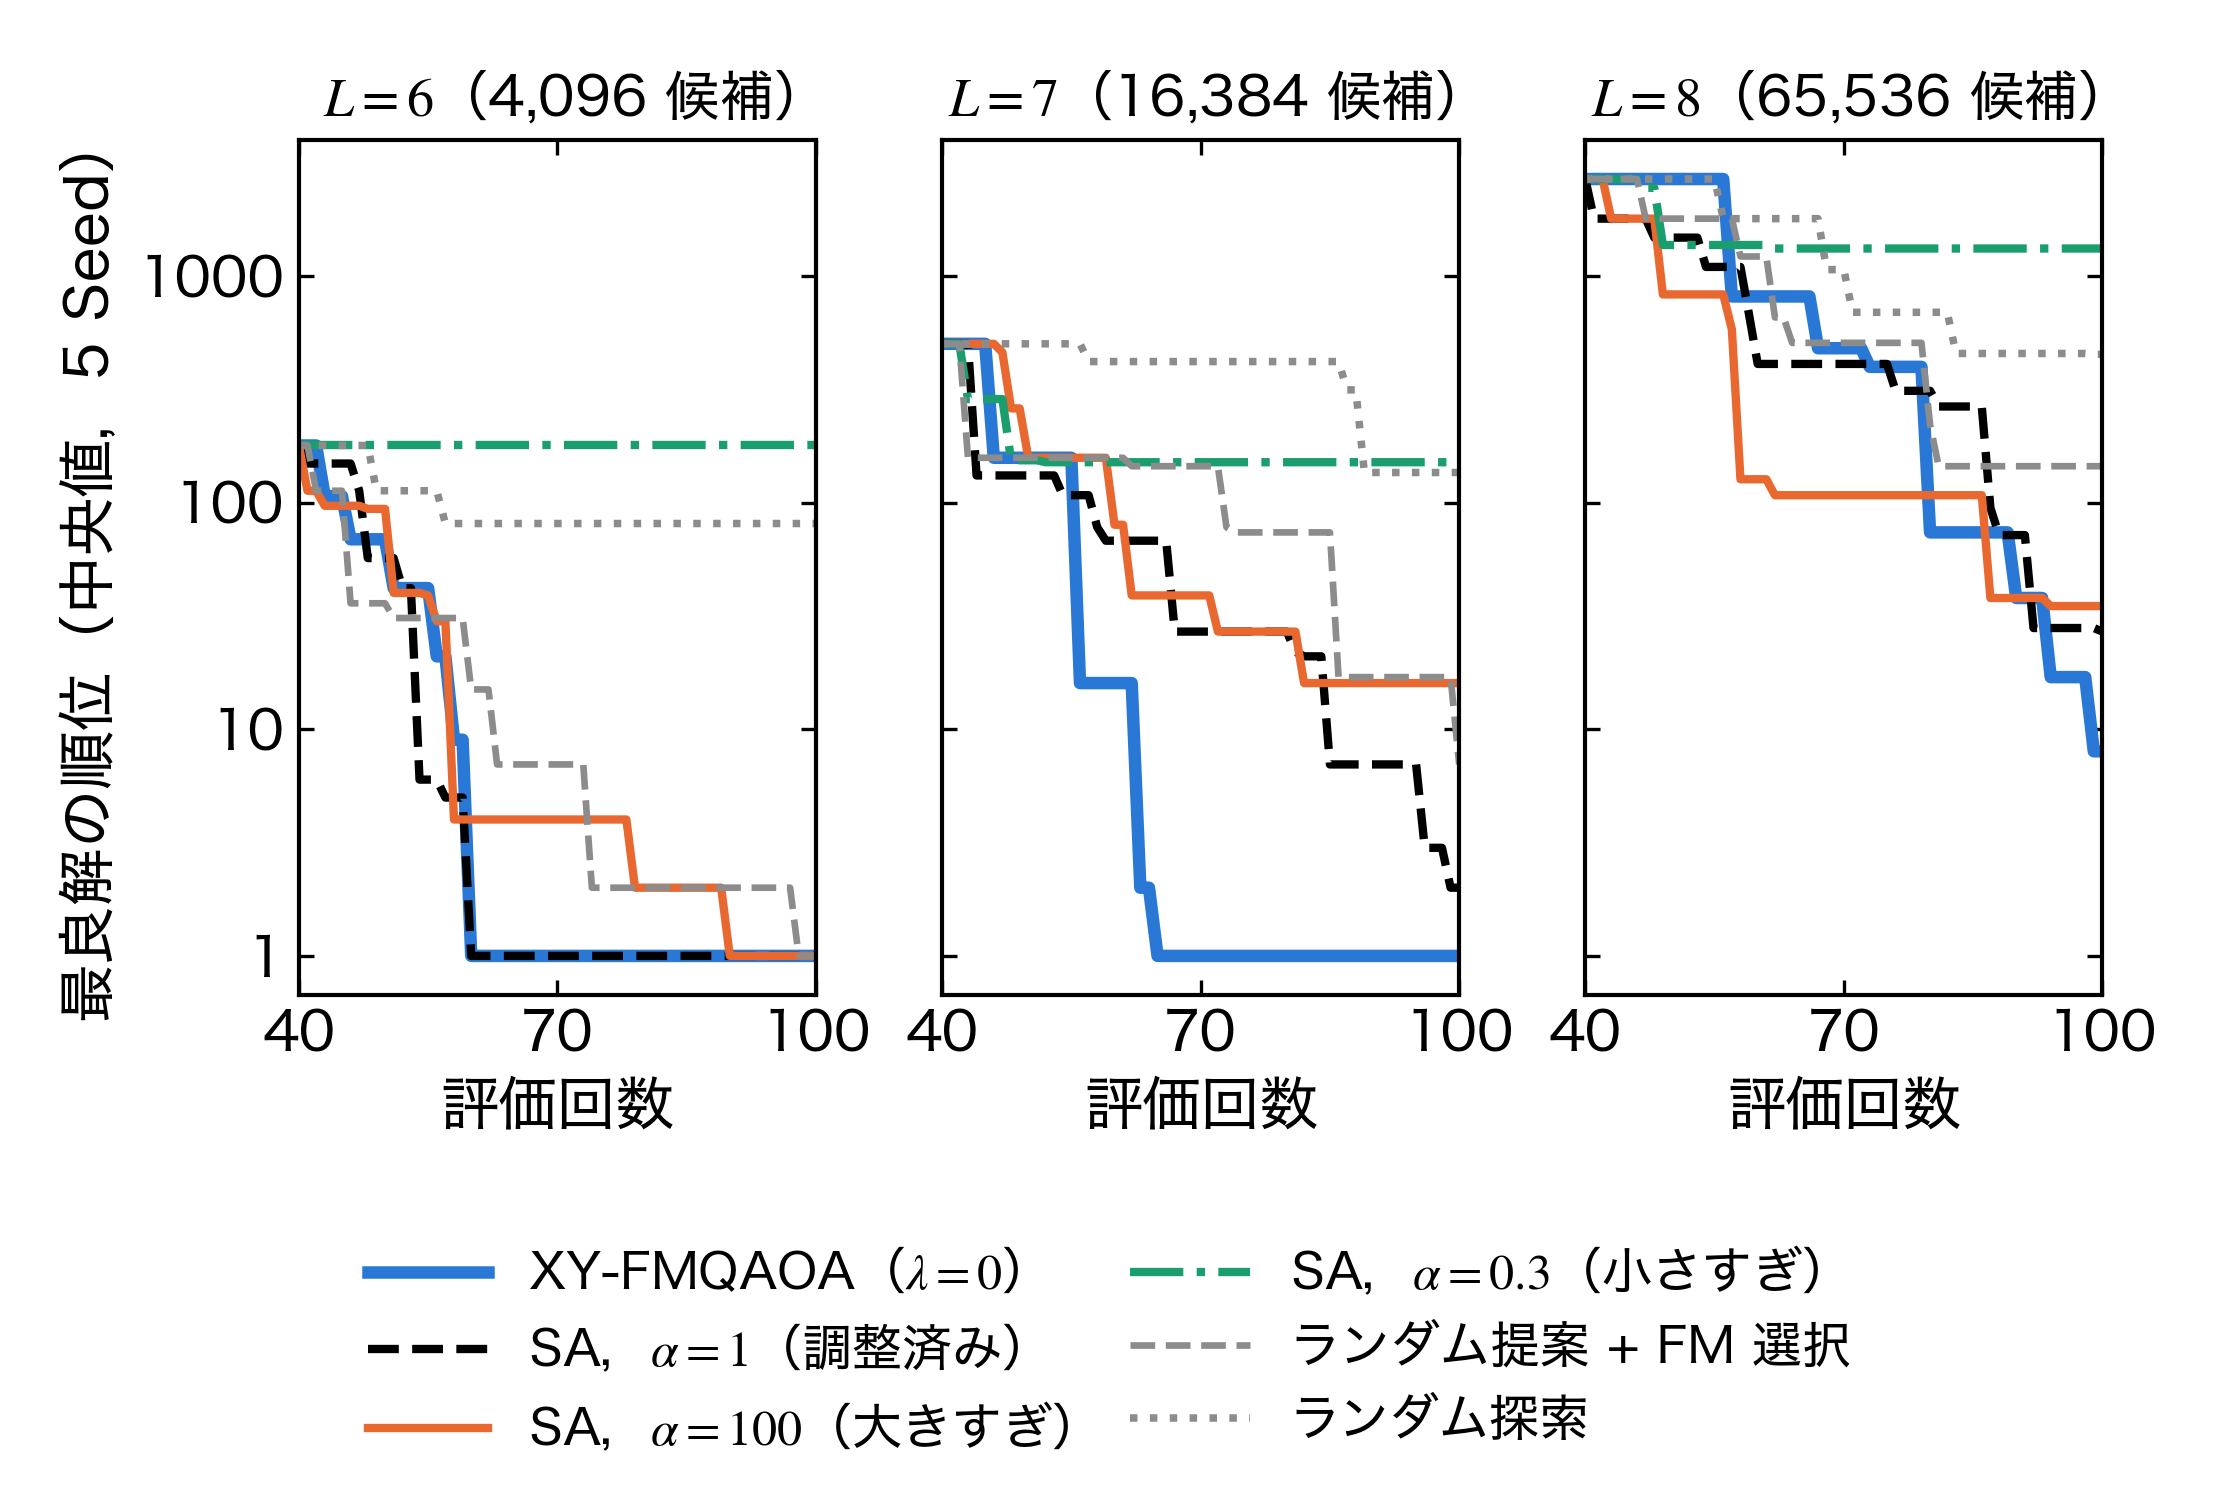

In [11]:
def fig_explore():
    rows = read("slide24_explore.csv")
    style = dict(M, Random=dict(color=GRAY, ls=":", lw=1.8, label="ランダム探索"))
    with plt.rc_context(JA_RC):
        fig, axes = plt.subplots(1, 3, figsize=(FW, FH), sharey=True)
        for ax, L in zip(axes, (6, 7, 8)):
            for c in ("XY-FMQAOA", "alpha1", "alpha100", "alpha0.3", "RandomFM", "Random"):
                r = sorted((x for x in rows if x["layers"] == L and x["condition"] == c), key=lambda x: x["evaluations"])
                if r:
                    st = style[c]
                    ax.plot([x["evaluations"] for x in r], [x["best_rank_median"] for x in r], color=st["color"], ls=st["ls"], lw=st["lw"], label=st["label"])
            ax.set_yscale("log"); log_ticks(ax.yaxis, [1, 10, 100, 1000]); ax.set_xlim(40, 100); ax.set_xticks([40, 70, 100])
            ax.set_xlabel("評価回数"); ax.set_title(f"$L={L}$（{NCAND[L]} 候補）", fontsize=13)
        axes[0].set_ylabel("最良解の順位（中央値，5 Seed）")
        h, l = axes[0].get_legend_handles_labels()
        fig.legend(h, l, loc="lower center", ncol=2, fontsize=12, handlelength=2.4, columnspacing=1.2)
        fig.tight_layout(rect=(0, 0.2, 1, 1), w_pad=0.6)
        save(fig, "slide_explore_L678")


fig_explore()

## 3. 確認

作図用 CSV の主な数値がスライドの記載と一致するかを確かめる。

In [12]:
def check():
    r18 = {r["condition"]: r for r in read("slide18_loop_alpha.csv")}
    r19 = {r["condition"]: r for r in read("slide19_confirm2.csv") if r["evaluations"] == 100}
    got = {
        "slide 18 optimum (alpha=1, alpha=10, alpha=100, alpha=1000, Adaptive, XY) / 15":
            [int(r18[c]["n_optimum"]) for c in ("alpha1", "alpha10", "alpha100", "alpha1000", "Adaptive", "XY-FMQAOA")],
        "slide 19 optimum at 100 evaluations (XY, alpha=1, CatSA, alpha=100, alpha=0.3) / 30":
            [round(r19[c]["frac_optimum"] * 30) for c in ("XY-FMQAOA", "alpha1", "CatSA", "alpha100", "alpha0.3")],
    }
    final2 = {}
    for r in read("confirm2_final.csv"):
        final2[r["condition"]] = final2.get(r["condition"], 0) + int(r["success"])
    got["confirm2_final.csv successes (same order)"] = [final2[c] for c in ("XY-FMQAOA", "alpha1", "CatSA", "alpha100", "alpha0.3")]
    for k, v in got.items():
        print(f"{k}: {v}")
    print("font:", FAMILY)


check()

slide 18 optimum (alpha=1, alpha=10, alpha=100, alpha=1000, Adaptive, XY) / 15: [9, 4, 2, 4, 8, 13]
slide 19 optimum at 100 evaluations (XY, alpha=1, CatSA, alpha=100, alpha=0.3) / 30: [23, 18, 16, 4, 2]
confirm2_final.csv successes (same order): [23, 18, 16, 4, 2]
font: Hiragino Sans
